# Feature Count Comparison

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

## Load Dataset

In [2]:
df = pd.read_csv('../data/processed/corn_belt_yield_weather_soil.csv', dtype={'fips': str})

In [3]:
df.shape

(24644, 106)

In [4]:
df.head()

,state_name,state_alpha,state_ansi,county_ansi,fips,county_name,year,short_desc,unit_desc,statisticcat_desc,...,vp_mean_pa_m12,sand_pct_0_30cm,silt_pct_0_30cm,clay_pct_0_30cm,organic_matter_pct_0_30cm,ph_0_30cm,bulk_density_g_cm3_0_30cm,ksat_um_s_0_30cm,available_water_storage_cm_0_100cm,slope_pct
0,ILLINOIS,IL,17,11,17011,BUREAU,2025,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,357.549355,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
1,ILLINOIS,IL,17,11,17011,BUREAU,2024,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,462.975000,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
2,ILLINOIS,IL,17,11,17011,BUREAU,2023,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,614.017097,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
3,ILLINOIS,IL,17,11,17011,BUREAU,2022,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,393.786774,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624
4,ILLINOIS,IL,17,11,17011,BUREAU,2021,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",BU / ACRE,YIELD,...,504.136452,12.94747,62.984117,24.068413,3.691334,6.516119,1.363566,11.164841,18.336345,4.666624


## Split Data into Training, Validation, and Testing Sets

The data split will consitst of:
- A training dataset from 2000-2017 which will learn feature rankings and fit the models
- A validation dataset from 2018-2020 which will compare models and make decision about their settings
- A testing dataset from 2021 - 2025 which will report performance after those decisions are settled. 

In [5]:
train = df[(df['year'] >= 2000) & (df['year'] <= 2017)]
y_train = train['Value']

validation = df[(df['year'] >= 2018) & (df['year'] <= 2020)]
y_validation = validation['Value']

test = df[(df['year'] >= 2021) & (df['year'] <= 2025)]
y_test = test['Value']

In [6]:
train.shape

(17919, 106)

In [7]:
validation.shape

(2561, 106)

In [8]:
test.shape

(4164, 106)

In [9]:
df.shape == (train.shape[0] + validation.shape[0] + test.shape[0], train.shape[1])

True

In [10]:
train['year'].min()

2000

In [11]:
train['year'].max()

2017

In [12]:
validation['year'].min()

2018

In [13]:
validation['year'].max()

2020

In [14]:
test['year'].min()

2021

In [15]:
test['year'].max()

2025

## Define Environmental Features

In [16]:
# weather
weather_cols = ['prcp_total_mm_m01', 'prcp_total_mm_m02', 'prcp_total_mm_m03', 'prcp_total_mm_m04', 'prcp_total_mm_m06', 'prcp_total_mm_m05', 'prcp_total_mm_m07', 'prcp_total_mm_m08', 'prcp_total_mm_m09', 'prcp_total_mm_m10', 'prcp_total_mm_m11', 'prcp_total_mm_m12', 'radiation_total_mj_m2_m01', 'radiation_total_mj_m2_m02', 'radiation_total_mj_m2_m03', 'radiation_total_mj_m2_m04', 'radiation_total_mj_m2_m05', 'radiation_total_mj_m2_m06', 'radiation_total_mj_m2_m07', 'radiation_total_mj_m2_m08', 'radiation_total_mj_m2_m09', 'radiation_total_mj_m2_m10', 'radiation_total_mj_m2_m11', 'radiation_total_mj_m2_m12', 'dayl_mean_s_m01', 'dayl_mean_s_m02', 'dayl_mean_s_m03', 'dayl_mean_s_m04', 'dayl_mean_s_m05', 'dayl_mean_s_m06', 'dayl_mean_s_m07', 'dayl_mean_s_m08', 'dayl_mean_s_m09', 'dayl_mean_s_m10', 'dayl_mean_s_m11', 'dayl_mean_s_m12', 'swe_mean_kg_m2_m01', 'swe_mean_kg_m2_m02', 'swe_mean_kg_m2_m03', 'swe_mean_kg_m2_m04', 'swe_mean_kg_m2_m05', 'swe_mean_kg_m2_m06', 'swe_mean_kg_m2_m07', 'swe_mean_kg_m2_m08', 'swe_mean_kg_m2_m09', 'swe_mean_kg_m2_m10', 'swe_mean_kg_m2_m11', 'swe_mean_kg_m2_m12', 'tmax_mean_c_m01', 'tmax_mean_c_m02', 'tmax_mean_c_m03', 'tmax_mean_c_m04', 'tmax_mean_c_m05', 'tmax_mean_c_m06', 'tmax_mean_c_m07', 'tmax_mean_c_m08', 'tmax_mean_c_m09', 'tmax_mean_c_m10', 'tmax_mean_c_m11', 'tmax_mean_c_m12', 'tmin_mean_c_m01', 'tmin_mean_c_m02', 'tmin_mean_c_m03', 'tmin_mean_c_m04', 'tmin_mean_c_m05', 'tmin_mean_c_m06', 'tmin_mean_c_m07', 'tmin_mean_c_m08', 'tmin_mean_c_m09', 'tmin_mean_c_m10', 'tmin_mean_c_m11', 'tmin_mean_c_m12', 'vp_mean_pa_m01', 'vp_mean_pa_m02', 'vp_mean_pa_m03', 'vp_mean_pa_m04', 'vp_mean_pa_m05', 'vp_mean_pa_m06', 'vp_mean_pa_m07', 'vp_mean_pa_m08', 'vp_mean_pa_m09', 'vp_mean_pa_m10', 'vp_mean_pa_m11', 'vp_mean_pa_m12']

In [17]:
# soil
soil_cols = ['sand_pct_0_30cm', 'silt_pct_0_30cm', 'clay_pct_0_30cm', 'organic_matter_pct_0_30cm', 'ph_0_30cm', 'bulk_density_g_cm3_0_30cm', 'ksat_um_s_0_30cm', 'available_water_storage_cm_0_100cm', 'slope_pct']

In [18]:
# weather + soil
environment_cols = weather_cols + soil_cols

In [19]:
# context features
context_cols = ['year', 'latitude', 'longitude']

In [20]:
# target feature
target_col = "Value"

In [21]:
# quick check
len(weather_cols)

84

In [22]:
len(soil_cols)

9

In [23]:
len(environment_cols)

93

In [24]:
len(context_cols)

3

## Remove Constant Features

I have three columns with values of all zeros `swe_mean_kg_m2_m07`, `swe_mean_kg_m2_m08`, and `swe_mean_kg_m2_m09`. These are the snow water equivalent for July, August, and September. These columns are constant at zero in our dataset, so it is best to remove these featuers as it will mess with our correlations and machine learning algorithms later on.

In [25]:
len(environment_cols)

93

In [26]:
temp_cols = weather_cols + soil_cols

In [27]:
variance_filter = VarianceThreshold(threshold=0.0)
variance_filter.fit(train[temp_cols])

,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0


In [28]:
environment_cols = variance_filter.get_feature_names_out().tolist()

In [29]:
for col in temp_cols:
    if col not in environment_cols:
        print(f"Removed: {col}")

Removed: swe_mean_kg_m2_m07
Removed: swe_mean_kg_m2_m08
Removed: swe_mean_kg_m2_m09


In [30]:
len(environment_cols)

90

## Pearson Correlations

In [31]:
pearson = train[environment_cols].corrwith(y_train, method='pearson')
pearson_results = pearson.to_frame(name='Pearson')

pearson_results['Pearson_abs'] = pearson.abs().to_frame()

pearson_results = pearson_results.sort_values('Pearson_abs', ascending=False)

top_pearson = pearson_results.head(15)
top_pearson

,Pearson,Pearson_abs
tmax_mean_c_m07,-0.338718,0.338718
available_water_storage_cm_0_100cm,0.294431,0.294431
radiation_total_mj_m2_m06,-0.293151,0.293151
tmax_mean_c_m08,-0.290827,0.290827
prcp_total_mm_m07,0.264290,0.264290
prcp_total_mm_m06,0.211564,0.211564
vp_mean_pa_m06,0.196009,0.196009
prcp_total_mm_m08,0.190069,0.190069
radiation_total_mj_m2_m07,-0.179004,0.179004
radiation_total_mj_m2_m04,-0.167017,0.167017


In [32]:
pearson_top_15_cols = top_pearson.index.tolist()
pearson_top_15_cols

['tmax_mean_c_m07',
 'available_water_storage_cm_0_100cm',
 'radiation_total_mj_m2_m06',
 'tmax_mean_c_m08',
 'prcp_total_mm_m07',
 'prcp_total_mm_m06',
 'vp_mean_pa_m06',
 'prcp_total_mm_m08',
 'radiation_total_mj_m2_m07',
 'radiation_total_mj_m2_m04',
 'vp_mean_pa_m09',
 'tmin_mean_c_m06',
 'slope_pct',
 'tmax_mean_c_m01',
 'tmin_mean_c_m10']

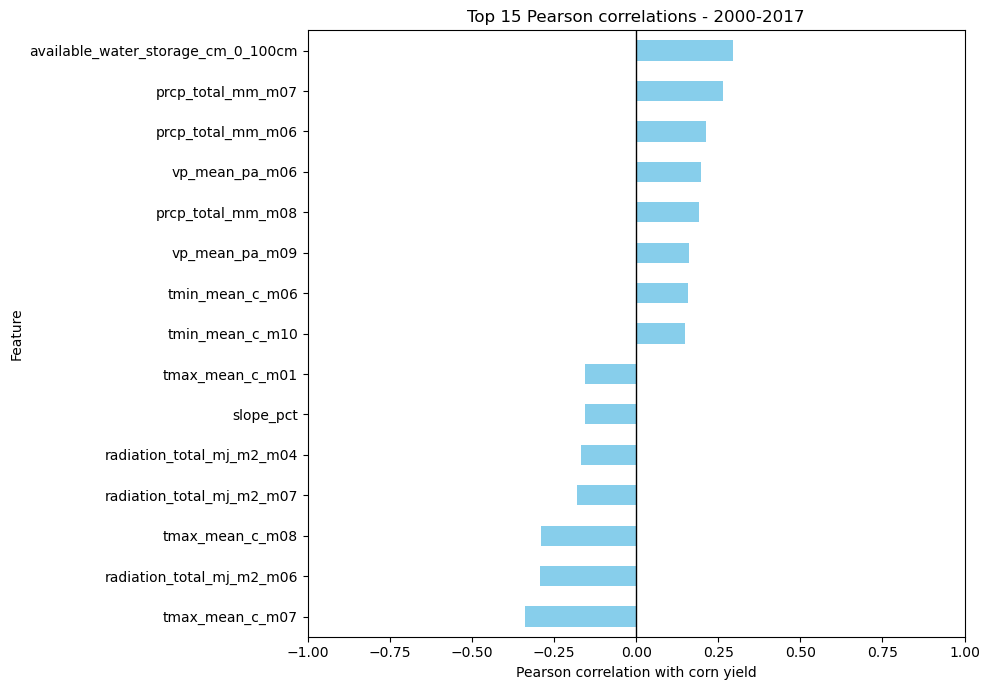

In [33]:
top_pearson['Pearson'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1,1)
plt.xlabel("Pearson correlation with corn yield")
plt.ylabel("Feature")
plt.title("Top 15 Pearson correlations - 2000-2017")
plt.tight_layout()
plt.show()

## Spearman Correlations

In [34]:
spearman = train[environment_cols].corrwith(y_train, method='spearman')
spearman_results = spearman.to_frame(name='Spearman')

spearman_results['Spearman_abs'] = spearman.abs().to_frame()

spearman_results = spearman_results.sort_values('Spearman_abs', ascending=False)

top_spearman = spearman_results.head(15)
top_spearman

,Spearman,Spearman_abs
available_water_storage_cm_0_100cm,0.329191,0.329191
tmax_mean_c_m07,-0.299132,0.299132
tmax_mean_c_m08,-0.289334,0.289334
prcp_total_mm_m07,0.268317,0.268317
radiation_total_mj_m2_m06,-0.246042,0.246042
prcp_total_mm_m06,0.219734,0.219734
prcp_total_mm_m08,0.192849,0.192849
slope_pct,-0.171348,0.171348
radiation_total_mj_m2_m04,-0.163808,0.163808
tmax_mean_c_m01,-0.163056,0.163056


In [35]:
spearman_top_15_cols = top_spearman.index.tolist()
spearman_top_15_cols

['available_water_storage_cm_0_100cm',
 'tmax_mean_c_m07',
 'tmax_mean_c_m08',
 'prcp_total_mm_m07',
 'radiation_total_mj_m2_m06',
 'prcp_total_mm_m06',
 'prcp_total_mm_m08',
 'slope_pct',
 'radiation_total_mj_m2_m04',
 'tmax_mean_c_m01',
 'prcp_total_mm_m04',
 'vp_mean_pa_m06',
 'radiation_total_mj_m2_m07',
 'silt_pct_0_30cm',
 'swe_mean_kg_m2_m01']

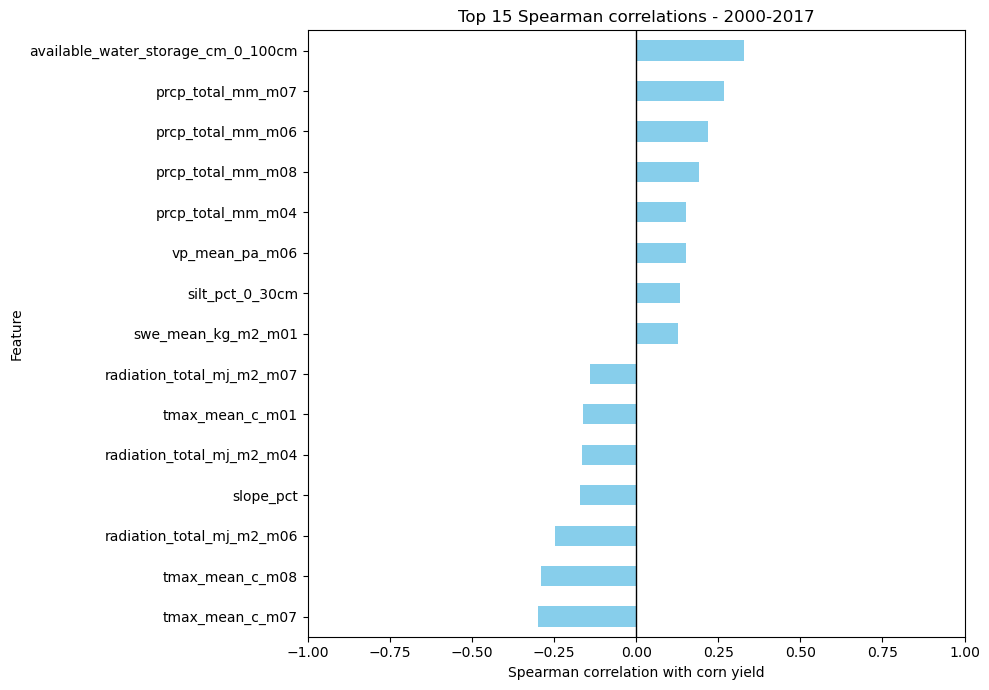

In [36]:
top_spearman['Spearman'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1,1)
plt.xlabel("Spearman correlation with corn yield")
plt.ylabel("Feature")
plt.title("Top 15 Spearman correlations - 2000-2017")
plt.tight_layout()
plt.show()

## Random Forest Feature Importance

In [37]:
X_train = train[environment_cols]
X_train.shape

(17919, 90)

I am adding the `n_jobs=-2` parameter to the random forest. This lets my computer use all CPU cores but one in parallel. If you put `n_jobs=-1`, you will use all of your CPU cores, but I want to leave just one so my system is responsive. 

[https://scikit-learn.org/stable/glossary.html#term-n_jobs](https://scikit-learn.org/stable/glossary.html#term-n_jobs)

In [38]:
forest = RandomForestRegressor(random_state=110, n_jobs=-2)

In [39]:
forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [40]:
rf_results = pd.DataFrame({"Random Forest": forest.feature_importances_},index=X_train.columns)

rf_results = rf_results.sort_values("Random Forest", ascending=False)

top_rf = rf_results.head(15)
top_rf

,Random Forest
tmax_mean_c_m07,0.157421
available_water_storage_cm_0_100cm,0.105946
tmin_mean_c_m06,0.101604
tmax_mean_c_m08,0.062577
ksat_um_s_0_30cm,0.052148
prcp_total_mm_m07,0.019788
vp_mean_pa_m06,0.018761
tmin_mean_c_m09,0.018330
organic_matter_pct_0_30cm,0.017301
bulk_density_g_cm3_0_30cm,0.015889


In [41]:
rf_top_15_cols = top_rf.index.tolist()
rf_top_15_cols

['tmax_mean_c_m07',
 'available_water_storage_cm_0_100cm',
 'tmin_mean_c_m06',
 'tmax_mean_c_m08',
 'ksat_um_s_0_30cm',
 'prcp_total_mm_m07',
 'vp_mean_pa_m06',
 'tmin_mean_c_m09',
 'organic_matter_pct_0_30cm',
 'bulk_density_g_cm3_0_30cm',
 'slope_pct',
 'tmin_mean_c_m05',
 'ph_0_30cm',
 'clay_pct_0_30cm',
 'radiation_total_mj_m2_m06']

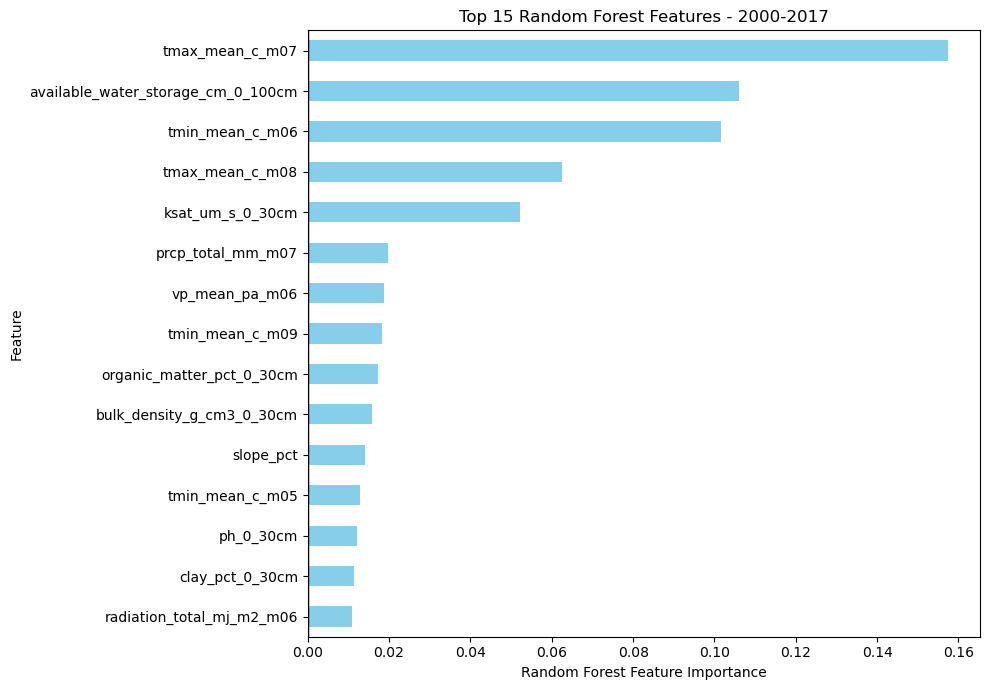

In [42]:
top_rf['Random Forest'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(left=0)
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Features - 2000-2017")
plt.tight_layout()
plt.show()

## Preparing Prediction Inputs

For the datasets with the different featurs selected by the correlations and feature importance, I want to use all of the variables I can. This includes the year, latitude, and longitude which will give context to our prediction models.

In [43]:
all_input_cols = context_cols + environment_cols
pearson_input_cols = context_cols + pearson_top_15_cols
spearman_input_cols = context_cols + spearman_top_15_cols
rf_input_cols = context_cols + rf_top_15_cols

print("All features:", len(all_input_cols))
print("Pearson-selected:", len(pearson_input_cols))
print("Spearman-selected:", len(spearman_input_cols))
print("RF-selected:", len(rf_input_cols))

All features: 93
Pearson-selected: 18
Spearman-selected: 18
RF-selected: 18


In [44]:
# All environmental features plus context
X_train_all = train[all_input_cols].copy()
X_validation_all = validation[all_input_cols].copy()
X_test_all = test[all_input_cols].copy()

In [45]:
# Pearson selected features plus context
X_train_pearson = train[pearson_input_cols].copy()
X_validation_pearson = validation[pearson_input_cols].copy()
X_test_pearson = test[pearson_input_cols].copy()

In [46]:
# Spearman selected features plus context
X_train_spearman = train[spearman_input_cols].copy()
X_validation_spearman = validation[spearman_input_cols].copy()
X_test_spearman = test[spearman_input_cols].copy()

In [47]:
# Random Forest selected features plus context
X_train_rf = train[rf_input_cols].copy()
X_validation_rf = validation[rf_input_cols].copy()
X_test_rf = test[rf_input_cols].copy()

In [48]:
# Quick Check
print("All:", X_validation_all.shape)
print("Pearson:", X_validation_pearson.shape)
print("Spearman:", X_validation_spearman.shape)
print("Random Forest:", X_validation_rf.shape)

All: (2561, 93)
Pearson: (2561, 18)
Spearman: (2561, 18)
Random Forest: (2561, 18)


# Baseline Prediction

A simple baseline model for each county's yield is created by taking the average of the yield from the years 2000-2017. This baseline is a reference for the prediciton models to compare to. 

In [49]:
# Calculate each county's average yield using training data
county_mean_yield = train.groupby("fips")["Value"].mean()
county_mean_yield.head()

fips
17001    157.322222
17003    147.513333
17005    134.800000
17007    167.964706
17009    153.250000
Name: Value, dtype: float64

In [50]:
baseline_predictions = validation["fips"].map(county_mean_yield)
baseline_predictions.head()

5     178.650000
6     178.650000
7     178.650000
31    186.933333
32    186.933333
Name: fips, dtype: float64

In [51]:
baseline_predictions.isna().sum()

4

In [52]:
# Calculate state averages using training data
state_mean_yield = train.groupby("state_alpha")["Value"].mean()
state_mean_yield

state_alpha
IA    166.389346
IL    158.038845
IN    151.982006
KS    118.318411
KY    129.736697
MI    128.666918
MN    151.709172
MO    126.837212
ND    100.796154
NE    153.927055
OH    143.815058
SD    110.161863
WI    138.226364
Name: Value, dtype: float64

In [53]:
state_baseline_predictions = validation["state_alpha"].map(state_mean_yield)
baseline_predictions = baseline_predictions.fillna(state_baseline_predictions)

In [54]:
# Use the overall training average if a prediction is still missing
overall_mean_yield = train["Value"].mean()
baseline_predictions = baseline_predictions.fillna(overall_mean_yield)

In [55]:
print("Validation observations:", len(validation))
print("Baseline predictions:", len(baseline_predictions))
print("Missing predictions:", baseline_predictions.isna().sum())

Validation observations: 2561
Baseline predictions: 2561
Missing predictions: 0


## Evaluate Baseline model

We will compare the baseline model with the validation yields from 2018-2020. We will use Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and $R^2$. The lower the MAE, MSE, and RMSE the better while the higher $R^2$ is better.

In [56]:
# Calculate errors
baseline_errors = y_validation - baseline_predictions
baseline_errors

5        20.750000
6         1.250000
7        35.450000
31       12.766667
32       19.166667
           ...    
24598    27.194444
24599    26.394444
24623    24.688889
24624    27.788889
24625    40.488889
Length: 2561, dtype: float64

In [57]:
# calculate Mean Absolute Error
baseline_mae = baseline_errors.abs().mean()
baseline_mae

26.7292702297434

In [58]:
# Calcualte  Mean Squared Error
baseline_mse = (baseline_errors ** 2).mean()
baseline_mse

943.5917208887042

In [59]:
# Calcualte Root Mean Squared Error
baseline_rmse = np.sqrt(baseline_mse)
baseline_rmse

30.717938096309528

In [60]:
# Calculate R^2
baseline_squared_error = (baseline_errors ** 2).sum()
validation_squared_variation = ((y_validation - y_validation.mean()) ** 2).sum()
baseline_r2 = 1 - (baseline_squared_error / validation_squared_variation)
baseline_r2

0.0665662799835911

In [61]:
baseline_results = pd.DataFrame({
    "Model": ["Historical County Average Baseline"],
    "MAE": [baseline_mae],
    "MSE": [baseline_mse],
    "RMSE": [baseline_rmse],
    "R2": [baseline_r2]
})

baseline_results

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.72927,943.591721,30.717938,0.066566


The historical county average baseline has an `MAE` of `26.73` bushels per acre, `MSE` of `943.59` squared bushels per squared acre, and an `RMSE` of `30.72` bushels per acre. The $R^2$ was `0.067` whcih means about 6.7% less total squared error than redicting the validation mean for every observation. 

A lower MAE, MSE, and RMSE correlate to a better prediction performance whcih a higher $R^2$ indicates better performance.

These are a reference for evaluating if the prediciton models improve with the feature selections compared to this baseline.

# Random Forest

## Random Forest Prediction With All Features

In [62]:
print("Training inputs:", X_train_all.shape)
print("Validation inputs:", X_validation_all.shape)

Training inputs: (17919, 93)
Validation inputs: (2561, 93)


In [63]:
# Create Model
rf_all = RandomForestRegressor(random_state=110, n_jobs=-2)

In [64]:
# Train model
rf_all.fit(X_train_all, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [65]:
# Predictions
rf_all_predictions = rf_all.predict(X_validation_all)

In [66]:
rf_all_predictions

array([194.98 , 189.574, 172.513, ..., 160.177, 150.73 , 145.902])

In [67]:
# turn this into a dataframe

In [68]:
rf_all_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": rf_all_predictions
}, index=X_validation_all.index)

rf_all_preview.head()

,Actual yield,Predicted yield
5,199.4,194.980
6,179.9,189.574
7,214.1,172.513
31,199.7,199.026
32,206.1,191.614


In [69]:
len(y_validation)

2561

In [70]:
len(rf_all_predictions)

2561

### Evaluate Random Forest Model

In [71]:
rf_all_errors = (rf_all_preview["Actual yield"] - rf_all_preview["Predicted yield"])
rf_all_errors.head()

5      4.420
6     -9.674
7     41.587
31     0.674
32    14.486
dtype: float64

In [72]:
rf_all_mae = rf_all_errors.abs().mean()
rf_all_mse = (rf_all_errors ** 2).mean()
rf_all_rmse = np.sqrt(rf_all_mse)
rf_all_squared_error = (rf_all_errors ** 2).sum()
rf_all_r2 = 1 - (rf_all_squared_error / validation_squared_variation)

In [73]:
rf_all_results = pd.DataFrame({
    "Model": ["Random Forest All Features"],
    "MAE": [rf_all_mae],
    "MSE": [rf_all_mse],
    "RMSE": [rf_all_rmse],
    "R2": [rf_all_r2]
})

rf_all_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest All Features,17.530756,480.97601,21.931165,0.524202


In [74]:
model_comparison = pd.concat([baseline_results, rf_all_results], ignore_index=True)
model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202


## Random Forest Prediction With Pearson Correlation Selected Features

In [75]:
print("Training inputs:", X_train_pearson.shape)
print("Validation inputs:", X_validation_pearson.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [76]:
# Create Model
rf_pearson = RandomForestRegressor(random_state=110, n_jobs=-2)

In [77]:
# Train model
rf_pearson.fit(X_train_pearson, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [78]:
# Predictions
rf_pearson_predictions = rf_pearson.predict(X_validation_pearson)

In [79]:
rf_pearson_predictions

array([206.953, 201.399, 201.841, ..., 148.361, 160.765, 167.233])

In [80]:
rf_pearson_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": rf_pearson_predictions
}, index=X_validation_pearson.index)

rf_pearson_preview.head()

,Actual yield,Predicted yield
5,199.4,206.953
6,179.9,201.399
7,214.1,201.841
31,199.7,169.754
32,206.1,199.152


In [81]:
len(rf_pearson_predictions)

2561

### Evaluate Random Forest Model

In [82]:
rf_pearson_errors = (rf_pearson_preview["Actual yield"] - rf_pearson_preview["Predicted yield"])
rf_pearson_errors.head()

5     -7.553
6    -21.499
7     12.259
31    29.946
32     6.948
dtype: float64

In [83]:
rf_pearson_mae = rf_pearson_errors.abs().mean()
rf_pearson_mse = (rf_pearson_errors ** 2).mean()
rf_pearson_rmse = np.sqrt(rf_pearson_mse)
rf_pearson_squared_error = (rf_pearson_errors ** 2).sum()
rf_pearson_r2 = 1 - (rf_pearson_squared_error / validation_squared_variation)

In [84]:
rf_pearson_results = pd.DataFrame({
    "Model": ["Random Forest Pearson Features"],
    "MAE": [rf_pearson_mae],
    "MSE": [rf_pearson_mse],
    "RMSE": [rf_pearson_rmse],
    "R2": [rf_pearson_r2]
})

rf_pearson_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Pearson Features,16.79395,441.469071,21.011165,0.563283


In [85]:
model_comparison = pd.concat([baseline_results, rf_all_results, rf_pearson_results], ignore_index=True)
model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283


## Random Forest Prediction With Spearman Correlation Selected Features

In [86]:
print("Training inputs:", X_train_spearman.shape)
print("Validation inputs:", X_validation_spearman.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [87]:
# Create Model
rf_spearman = RandomForestRegressor(random_state=110, n_jobs=-2)

In [88]:
# Train model
rf_spearman.fit(X_train_spearman, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [89]:
# Predictions
rf_spearman_predictions = rf_spearman.predict(X_validation_spearman)

In [90]:
rf_spearman_predictions

array([212.028, 207.417, 205.986, ..., 172.385, 162.832, 171.057])

In [91]:
rf_spearman_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": rf_spearman_predictions
}, index=X_validation_spearman.index)

rf_spearman_preview.head()

,Actual yield,Predicted yield
5,199.4,212.028
6,179.9,207.417
7,214.1,205.986
31,199.7,217.078
32,206.1,207.792


In [92]:
len(rf_spearman_predictions)

2561

### Evaluate Random Forest Model

In [93]:
rf_spearman_errors = (rf_spearman_preview["Actual yield"] - rf_spearman_preview["Predicted yield"])
rf_spearman_errors.head()

5    -12.628
6    -27.517
7      8.114
31   -17.378
32    -1.692
dtype: float64

In [94]:
rf_spearman_mae = rf_spearman_errors.abs().mean()
rf_spearman_mse = (rf_spearman_errors ** 2).mean()
rf_spearman_rmse = np.sqrt(rf_spearman_mse)
rf_spearman_squared_error = (rf_spearman_errors ** 2).sum()
rf_spearman_r2 = 1 - (rf_spearman_squared_error / validation_squared_variation)

In [95]:
rf_spearman_results = pd.DataFrame({
    "Model": ["Random Forest Spearman Features"],
    "MAE": [rf_spearman_mae],
    "MSE": [rf_spearman_mse],
    "RMSE": [rf_spearman_rmse],
    "R2": [rf_spearman_r2]
})

rf_spearman_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181


In [96]:
model_comparison = pd.concat([baseline_results, rf_all_results, rf_pearson_results, rf_spearman_results], ignore_index=True)
model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181


## Random Forest Prediction With RF Feature Importance Selected Features

In [97]:
print("Training inputs:", X_train_rf.shape)
print("Validation inputs:", X_validation_rf.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [98]:
# Create Model
rf_selected = RandomForestRegressor(random_state=110, n_jobs=-2)

In [99]:
# Train model
rf_selected.fit(X_train_rf, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [100]:
# Predictions
rf_selected_predictions = rf_selected.predict(X_validation_rf)

In [101]:
rf_selected_predictions

array([210.462, 199.328, 194.258, ..., 169.188, 158.295, 167.375])

In [102]:
rf_selected_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": rf_selected_predictions
}, index=X_validation_rf.index)

rf_selected_preview.head()

,Actual yield,Predicted yield
5,199.4,210.462
6,179.9,199.328
7,214.1,194.258
31,199.7,211.205
32,206.1,210.011


In [103]:
len(rf_selected_predictions)

2561

### Evaluate Random Forest Model

In [104]:
rf_selected_errors = (rf_selected_preview["Actual yield"] - rf_selected_preview["Predicted yield"])
rf_selected_errors.head()

5    -11.062
6    -19.428
7     19.842
31   -11.505
32    -3.911
dtype: float64

In [105]:
rf_selected_mae = rf_selected_errors.abs().mean()
rf_selected_mse = (rf_selected_errors ** 2).mean()
rf_selected_rmse = np.sqrt(rf_selected_mse)
rf_selected_squared_error = (rf_selected_errors ** 2).sum()
rf_selected_r2 = 1 - (rf_selected_squared_error / validation_squared_variation)

In [106]:
rf_selected_results = pd.DataFrame({
    "Model": ["Random Forest Selected Features"],
    "MAE": [rf_selected_mae],
    "MSE": [rf_selected_mse],
    "RMSE": [rf_selected_rmse],
    "R2": [rf_selected_r2]
})

rf_selected_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088


In [107]:
model_comparison = pd.concat([baseline_results, rf_all_results, rf_pearson_results, rf_spearman_results, rf_selected_results], ignore_index=True)
model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088


# Linear Regression

## Linear Regression Prediction With All Features

In [108]:
print("Training inputs:", X_train_all.shape)
print("Validation inputs:", X_validation_all.shape)

Training inputs: (17919, 93)
Validation inputs: (2561, 93)


In [109]:
# Scale the predictors
scaler_all = StandardScaler()

X_train_all_scaled = scaler_all.fit_transform(X_train_all)
X_validation_all_scaled = scaler_all.transform(X_validation_all)

In [110]:
# Create Model
lr_all = LinearRegression()

In [111]:
# Train Model
lr_all.fit(X_train_all_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [112]:
# Predictions
lr_all_predictions = lr_all.predict(X_validation_all_scaled)

In [113]:
lr_all_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": lr_all_predictions
}, index=X_validation_all.index)

lr_all_preview.head()

,Actual yield,Predicted yield
5,199.4,176.095840
6,179.9,158.308297
7,214.1,165.728299
31,199.7,178.108529
32,206.1,160.766458


In [114]:
len(lr_all_predictions)

2561

### Evaluate Linear Regression Model

In [115]:
lr_all_errors = (lr_all_preview["Actual yield"] - lr_all_preview["Predicted yield"])
lr_all_errors.head()

5     23.304160
6     21.591703
7     48.371701
31    21.591471
32    45.333542
dtype: float64

In [116]:
lr_all_mae = lr_all_errors.abs().mean()
lr_all_mse = (lr_all_errors ** 2).mean()
lr_all_rmse = np.sqrt(lr_all_mse)
lr_all_squared_error = (lr_all_errors ** 2).sum()
lr_all_r2 = 1 - (lr_all_squared_error / validation_squared_variation)

In [117]:
lr_all_results = pd.DataFrame({
    "Model": ["Linear Regression All Features"],
    "MAE": [lr_all_mae],
    "MSE": [lr_all_mse],
    "RMSE": [lr_all_rmse],
    "R2": [lr_all_r2]
})

lr_all_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243


In [118]:
model_comparison = pd.concat([baseline_results, rf_all_results, rf_pearson_results, rf_spearman_results, rf_selected_results, lr_all_results], ignore_index=True)
model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243


## Linear Regression Prediction With Pearson Correlation Selected Features

In [119]:
print("Training inputs:", X_train_pearson.shape)
print("Validation inputs:", X_validation_pearson.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [120]:
# Scale the predictors
scaler_pearson = StandardScaler()

X_train_pearson_scaled = scaler_pearson.fit_transform(X_train_pearson)
X_validation_pearson_scaled = scaler_pearson.transform(X_validation_pearson)

In [121]:
# Create Model
lr_pearson = LinearRegression()

In [122]:
# Train Model
lr_pearson.fit(X_train_pearson_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [123]:
# Predictions
lr_pearson_predictions = lr_pearson.predict(X_validation_pearson_scaled)

In [124]:
lr_pearson_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": lr_pearson_predictions
}, index=X_validation_pearson.index)

lr_pearson_preview.head()

,Actual yield,Predicted yield
5,199.4,164.713272
6,179.9,152.031746
7,214.1,168.672633
31,199.7,162.917216
32,206.1,154.234565


In [125]:
len(lr_pearson_predictions)

2561

### Evaluate Linear Regression Model

In [126]:
lr_pearson_errors = (lr_pearson_preview["Actual yield"] - lr_pearson_preview["Predicted yield"])
lr_pearson_errors.head()

5     34.686728
6     27.868254
7     45.427367
31    36.782784
32    51.865435
dtype: float64

In [127]:
lr_pearson_mae = lr_pearson_errors.abs().mean()
lr_pearson_mse = (lr_pearson_errors ** 2).mean()
lr_pearson_rmse = np.sqrt(lr_pearson_mse)
lr_pearson_squared_error = (lr_pearson_errors ** 2).sum()
lr_pearson_r2 = 1 - (lr_pearson_squared_error / validation_squared_variation)

In [128]:
lr_pearson_results = pd.DataFrame({
    "Model": ["Linear Regression Pearson Features"],
    "MAE": [lr_pearson_mae],
    "MSE": [lr_pearson_mse],
    "RMSE": [lr_pearson_rmse],
    "R2": [lr_pearson_r2]
})

lr_pearson_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression Pearson Features,25.678334,949.36911,30.811834,0.060851


In [129]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851


## Linear Regression Prediction With Spearman Correlation Selected Features

In [130]:
print("Training inputs:", X_train_spearman.shape)
print("Validation inputs:", X_validation_spearman.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [131]:
# Scale the predictors
scaler_spearman = StandardScaler()

X_train_spearman_scaled = scaler_spearman.fit_transform(X_train_spearman)
X_validation_spearman_scaled = scaler_spearman.transform(X_validation_spearman)

In [132]:
# Create Model
lr_spearman = LinearRegression()

In [133]:
# Train Model
lr_spearman.fit(X_train_spearman_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [134]:
# Predictions
lr_spearman_predictions = lr_spearman.predict(X_validation_spearman_scaled)

In [135]:
lr_spearman_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": lr_spearman_predictions
}, index=X_validation_spearman.index)

lr_spearman_preview.head()

,Actual yield,Predicted yield
5,199.4,158.117436
6,179.9,163.196439
7,214.1,170.455187
31,199.7,155.080615
32,206.1,162.266672


In [136]:
len(lr_spearman_predictions)

2561

### Evaluate Linear Regression Model

In [137]:
lr_spearman_errors = (lr_spearman_preview["Actual yield"] - lr_spearman_preview["Predicted yield"])
lr_spearman_errors.head()

5     41.282564
6     16.703561
7     43.644813
31    44.619385
32    43.833328
dtype: float64

In [138]:
lr_spearman_mae = lr_spearman_errors.abs().mean()
lr_spearman_mse = (lr_spearman_errors ** 2).mean()
lr_spearman_rmse = np.sqrt(lr_spearman_mse)
lr_spearman_squared_error = (lr_spearman_errors ** 2).sum()
lr_spearman_r2 = 1 - (lr_spearman_squared_error / validation_squared_variation)

In [139]:
lr_spearman_results = pd.DataFrame({
    "Model": ["Linear Regression Spearman Features"],
    "MAE": [lr_spearman_mae],
    "MSE": [lr_spearman_mse],
    "RMSE": [lr_spearman_rmse],
    "R2": [lr_spearman_r2]
})

lr_spearman_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002


In [140]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results,
    lr_spearman_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851
7,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002


## Linear Regression Prediction With RF Feature Importance Selected Features

In [141]:
print("Training inputs:", X_train_rf.shape)
print("Validation inputs:", X_validation_rf.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [142]:
# Scale the predictors
scaler_rf = StandardScaler()

X_train_rf_scaled = scaler_rf.fit_transform(X_train_rf)
X_validation_rf_scaled = scaler_rf.transform(X_validation_rf)

In [143]:
# Create Model
lr_selected = LinearRegression()

In [144]:
# Train Model
lr_selected.fit(X_train_rf_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [145]:
# Predictions
lr_selected_predictions = lr_selected.predict(X_validation_rf_scaled)

In [146]:
lr_selected_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": lr_selected_predictions
}, index=X_validation_rf.index)

lr_selected_preview.head()

,Actual yield,Predicted yield
5,199.4,176.213615
6,179.9,162.013206
7,214.1,185.259000
31,199.7,178.960838
32,206.1,170.911637


In [147]:
len(lr_selected_predictions)

2561

### Evaluate Linear Regression Model

In [148]:
lr_selected_errors = (lr_selected_preview["Actual yield"] - lr_selected_preview["Predicted yield"])
lr_selected_errors.head()

5     23.186385
6     17.886794
7     28.841000
31    20.739162
32    35.188363
dtype: float64

In [149]:
lr_selected_mae = lr_selected_errors.abs().mean()
lr_selected_mse = (lr_selected_errors ** 2).mean()
lr_selected_rmse = np.sqrt(lr_selected_mse)
lr_selected_squared_error = (lr_selected_errors ** 2).sum()
lr_selected_r2 = 1 - (lr_selected_squared_error / validation_squared_variation)

In [150]:
lr_selected_results = pd.DataFrame({
    "Model": ["Linear Regression RF Selected Features"],
    "MAE": [lr_selected_mae],
    "MSE": [lr_selected_mse],
    "RMSE": [lr_selected_rmse],
    "R2": [lr_selected_r2]
})

lr_selected_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718


In [151]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results,
    lr_spearman_results,
    lr_selected_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851
7,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002
8,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718


# Neural Network

[https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)

## Neural Network Prediction With All Features

In [152]:
print("Training inputs:", X_train_all.shape)
print("Validation inputs:", X_validation_all_scaled.shape)

Training inputs: (17919, 93)
Validation inputs: (2561, 93)


In [153]:
# Create Model
nn_all = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [154]:
# Train Model
nn_all.fit(X_train_all_scaled, y_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [155]:
# How many epochs?
nn_all.n_iter_

595

In [156]:
# Predictions
nn_all_predictions = nn_all.predict(X_validation_all_scaled)

In [157]:
nn_all_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": nn_all_predictions
}, index=X_validation_all.index)

nn_all_preview.head()

,Actual yield,Predicted yield
5,199.4,172.929523
6,179.9,173.562418
7,214.1,208.223552
31,199.7,173.958747
32,206.1,181.145347


In [158]:
len(nn_all_predictions)

2561

### Evaluate Neural Network Model

In [159]:
nn_all_errors = (nn_all_preview["Actual yield"] - nn_all_preview["Predicted yield"])
nn_all_errors.head()

5     26.470477
6      6.337582
7      5.876448
31    25.741253
32    24.954653
dtype: float64

In [160]:
nn_all_mae = nn_all_errors.abs().mean()
nn_all_mse = (nn_all_errors ** 2).mean()
nn_all_rmse = np.sqrt(nn_all_mse)
nn_all_squared_error = (nn_all_errors ** 2).sum()
nn_all_r2 = 1 - (nn_all_squared_error / validation_squared_variation)

In [161]:
nn_all_results = pd.DataFrame({
    "Model": ["Neural Network All Features"],
    "MAE": [nn_all_mae],
    "MSE": [nn_all_mse],
    "RMSE": [nn_all_rmse],
    "R2": [nn_all_r2]
})

nn_all_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network All Features,22.948271,812.879814,28.511047,0.195871


In [162]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results,
    lr_spearman_results,
    lr_selected_results,
    nn_all_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851
7,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002
8,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718
9,Neural Network All Features,22.948271,812.879814,28.511047,0.195871


## Neural Network Prediction With Pearson Correlation Selected Features

In [163]:
print("Training inputs:", X_train_pearson.shape)
print("Validation inputs:", X_validation_pearson_scaled.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [164]:
# Create Model
nn_pearson = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [165]:
# Train Model
nn_pearson.fit(X_train_pearson_scaled, y_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [166]:
# How many epochs?
nn_pearson.n_iter_

746

In [167]:
# Predictions
nn_pearson_predictions = nn_pearson.predict(X_validation_pearson_scaled)

In [168]:
nn_pearson_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": nn_pearson_predictions
}, index=X_validation_pearson.index)

nn_pearson_preview.head()

,Actual yield,Predicted yield
5,199.4,220.737547
6,179.9,213.769926
7,214.1,221.165228
31,199.7,217.558189
32,206.1,220.445397


In [169]:
len(nn_pearson_predictions)

2561

### Evaluate Neural Network Model

In [170]:
nn_pearson_errors = (nn_pearson_preview["Actual yield"] - nn_pearson_preview["Predicted yield"])
nn_pearson_errors.head()

5    -21.337547
6    -33.869926
7     -7.065228
31   -17.858189
32   -14.345397
dtype: float64

In [171]:
nn_pearson_mae = nn_pearson_errors.abs().mean()
nn_pearson_mse = (nn_pearson_errors ** 2).mean()
nn_pearson_rmse = np.sqrt(nn_pearson_mse)
nn_pearson_squared_error = (nn_pearson_errors ** 2).sum()
nn_pearson_r2 = 1 - (nn_pearson_squared_error / validation_squared_variation)

In [172]:
nn_pearson_results = pd.DataFrame({
    "Model": ["Neural Network Pearson Features"],
    "MAE": [nn_pearson_mae],
    "MSE": [nn_pearson_mse],
    "RMSE": [nn_pearson_rmse],
    "R2": [nn_pearson_r2]
})

nn_pearson_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network Pearson Features,18.378244,569.723889,23.86889,0.436409


In [173]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results,
    lr_spearman_results,
    lr_selected_results,
    nn_all_results,
    nn_pearson_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851
7,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002
8,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718
9,Neural Network All Features,22.948271,812.879814,28.511047,0.195871


## Neural Network Prediction With Spearman Correlation Selected Features

In [174]:
print("Training inputs:", X_train_spearman.shape)
print("Validation inputs:", X_validation_spearman_scaled.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [175]:
# Create Model
nn_spearman = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [176]:
# Train Model
nn_spearman.fit(X_train_spearman_scaled, y_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [177]:
# How many epochs?
nn_spearman.n_iter_

746

In [178]:
# Predictions
nn_spearman_predictions = nn_spearman.predict(X_validation_spearman_scaled)

In [179]:
nn_spearman_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": nn_spearman_predictions
}, index=X_validation_spearman.index)

nn_spearman_preview.head()

,Actual yield,Predicted yield
5,199.4,223.335688
6,179.9,207.216610
7,214.1,231.769446
31,199.7,234.178734
32,206.1,210.952588


In [180]:
len(nn_spearman_predictions)

2561

### Evaluate Neural Network Model

In [181]:
nn_spearman_errors = (nn_spearman_preview["Actual yield"] - nn_spearman_preview["Predicted yield"])
nn_spearman_errors.head()

5    -23.935688
6    -27.316610
7    -17.669446
31   -34.478734
32    -4.852588
dtype: float64

In [182]:
nn_spearman_mae = nn_spearman_errors.abs().mean()
nn_spearman_mse = (nn_spearman_errors ** 2).mean()
nn_spearman_rmse = np.sqrt(nn_spearman_mse)
nn_spearman_squared_error = (nn_spearman_errors ** 2).sum()
nn_spearman_r2 = 1 - (nn_spearman_squared_error / validation_squared_variation)

In [183]:
nn_spearman_results = pd.DataFrame({
    "Model": ["Neural Network Spearman Features"],
    "MAE": [nn_spearman_mae],
    "MSE": [nn_spearman_mse],
    "RMSE": [nn_spearman_rmse],
    "R2": [nn_spearman_r2]
})

nn_spearman_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network Spearman Features,18.133736,560.85616,23.682402,0.445182


In [184]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results,
    lr_spearman_results,
    lr_selected_results,
    nn_all_results,
    nn_pearson_results,
    nn_spearman_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851
7,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002
8,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718
9,Neural Network All Features,22.948271,812.879814,28.511047,0.195871


## Neural Network Prediction With RF Feature Importance Selected Features

In [185]:
print("Training inputs:", X_train_rf.shape)
print("Validation inputs:", X_validation_rf_scaled.shape)

Training inputs: (17919, 18)
Validation inputs: (2561, 18)


In [186]:
# Create Model
nn_selected = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [187]:
# Train Model
nn_selected.fit(X_train_rf_scaled, y_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [188]:
# How many epochs?
nn_selected.n_iter_

746

In [189]:
# Predictions
nn_selected_predictions = nn_selected.predict(X_validation_rf_scaled)

In [190]:
nn_selected_preview = pd.DataFrame({
    "Actual yield": y_validation,
    "Predicted yield": nn_selected_predictions
}, index=X_validation_rf.index)

nn_selected_preview.head()

,Actual yield,Predicted yield
5,199.4,221.152571
6,179.9,209.483626
7,214.1,204.409660
31,199.7,217.266862
32,206.1,219.904662


In [191]:
len(nn_selected_predictions)

2561

### Evaluate Neural Network Model

In [192]:
nn_selected_errors = (nn_selected_preview["Actual yield"] - nn_selected_preview["Predicted yield"])
nn_selected_errors.head()

5    -21.752571
6    -29.583626
7      9.690340
31   -17.566862
32   -13.804662
dtype: float64

In [193]:
nn_selected_mae = nn_selected_errors.abs().mean()
nn_selected_mse = (nn_selected_errors ** 2).mean()
nn_selected_rmse = np.sqrt(nn_selected_mse)
nn_selected_squared_error = (nn_selected_errors ** 2).sum()
nn_selected_r2 = 1 - (nn_selected_squared_error / validation_squared_variation)

In [194]:
nn_selected_results = pd.DataFrame({
    "Model": ["Neural Network RF Selected Features"],
    "MAE": [nn_selected_mae],
    "MSE": [nn_selected_mse],
    "RMSE": [nn_selected_rmse],
    "R2": [nn_selected_r2]
})

nn_selected_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network RF Selected Features,16.446481,466.377739,21.595781,0.538643


In [195]:
model_comparison = pd.concat([
    baseline_results,
    rf_all_results, 
    rf_pearson_results, 
    rf_spearman_results, 
    rf_selected_results, 
    lr_all_results, 
    lr_pearson_results,
    lr_spearman_results,
    lr_selected_results,
    nn_all_results,
    nn_pearson_results,
    nn_spearman_results,
    nn_selected_results
], ignore_index=True)

model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,26.729270,943.591721,30.717938,0.066566
1,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
4,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
5,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
6,Linear Regression Pearson Features,25.678334,949.369110,30.811834,0.060851
7,Linear Regression Spearman Features,24.055987,863.291154,29.381817,0.146002
8,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718
9,Neural Network All Features,22.948271,812.879814,28.511047,0.195871


# Validation Results Comparison

Models were trained using observations from 2000–2017 and evaluated using observations from 2018–2020.

Lower MAE, MSE, and RMSE indicate better predictions. Higher $R^2$ indicates better performance.

I am sorting the results by RMSE because it expresses prediction error in the original yield units of bushels per acre and gives greater influence to larger prediction errors.

[https://doi.org/10.5194/gmd-15-5481-2022](https://doi.org/10.5194/gmd-15-5481-2022)

In [196]:
validation_results = model_comparison.copy()

validation_results = validation_results.sort_values("RMSE")
validation_results = validation_results.reset_index(drop=True)

validation_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Spearman Features,14.700897,352.614641,18.778036,0.651181
1,Random Forest Selected Features,15.281266,375.959593,19.389677,0.628088
2,Random Forest Pearson Features,16.793950,441.469071,21.011165,0.563283
3,Neural Network RF Selected Features,16.446481,466.377739,21.595781,0.538643
4,Random Forest All Features,17.530756,480.976010,21.931165,0.524202
5,Neural Network Spearman Features,18.133736,560.856160,23.682402,0.445182
6,Neural Network Pearson Features,18.378244,569.723889,23.868890,0.436409
7,Linear Regression RF Selected Features,21.006845,670.500139,25.894017,0.336718
8,Linear Regression All Features,22.442325,771.057331,27.767919,0.237243
9,Neural Network All Features,22.948271,812.879814,28.511047,0.195871


In [197]:
feature_set_comparison = pd.DataFrame({
    "Feature set": [
        "All features",
        "Pearson",
        "Spearman",
        "RF importance"
    ],
    "Random Forest RMSE": [
        rf_all_rmse,
        rf_pearson_rmse,
        rf_spearman_rmse,
        rf_selected_rmse
    ],
    "Linear Regression RMSE": [
        lr_all_rmse,
        lr_pearson_rmse,
        lr_spearman_rmse,
        lr_selected_rmse
    ],
    "Neural Network RMSE": [
        nn_all_rmse,
        nn_pearson_rmse,
        nn_spearman_rmse,
        nn_selected_rmse
    ]
})

feature_set_comparison

,Feature set,Random Forest RMSE,Linear Regression RMSE,Neural Network RMSE
0,All features,21.931165,27.767919,28.511047
1,Pearson,21.011165,30.811834,23.868890
2,Spearman,18.778036,29.381817,23.682402
3,RF importance,19.389677,25.894017,21.595781


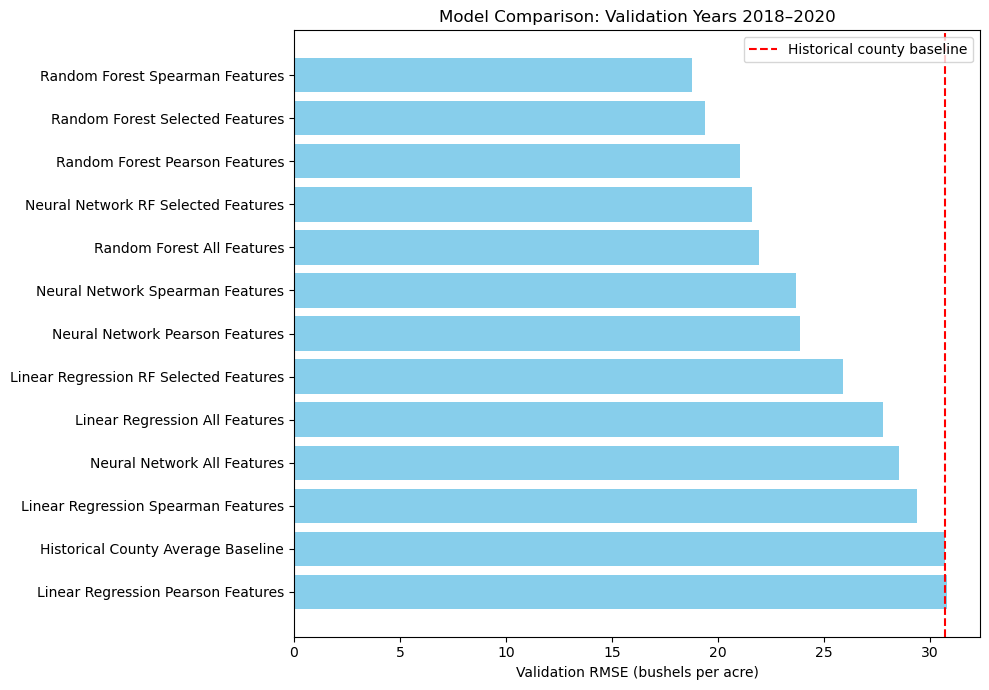

In [198]:
plt.figure(figsize=(10, 7))

plt.barh(validation_results["Model"], validation_results["RMSE"], color="skyblue")

plt.axvline(baseline_rmse, color="red", linestyle="--", label="Historical county baseline")

plt.gca().invert_yaxis()

plt.xlabel("Validation RMSE (bushels per acre)")
plt.title("Model Comparison: Validation Years 2018–2020")
plt.legend()
plt.tight_layout()
plt.show()

# Feature Count Comparison

I originally selected the top 15 environmental features for each selection method. To evaluate this choice, I will compare the top 1 through 20 features using the validation dataset.

The feature count with the lowest average validation RMSE across the nine combinations of selection methods and prediction models will be used for final testing.

Feature rankings are calculated using the 2000-2017 training data, and evaluation is performed using the 2018-2020 validation data.

## Set up the comparison

In [199]:
feature_counts = list(range(1,21))

feature_rankings = {
    "Pearson": pearson_results.index.tolist(),
    "Spearman": spearman_results.index.tolist(),
    "RF Importance": rf_results.index.tolist()
}

feature_count_results = []

## Compare Random Forest models

In [200]:
for count in feature_counts:
    for method, features in feature_rankings.items():

        selected_cols = context_cols + sorted(features[:count])

        X_train = train[selected_cols]
        X_validation = validation[selected_cols]

        model = RandomForestRegressor(random_state=110, n_jobs=-2)

        model.fit(X_train, y_train)

        predictions = model.predict(X_validation)

        rmse = np.sqrt(((y_validation - predictions) ** 2).mean())

        feature_count_results.append({
            "Features": count,
            "Method": method,
            "Model": "Random Forest",
            "RMSE": rmse
        })

        print(count, method, round(rmse, 2))

1 Pearson 20.62
1 Spearman 19.73
1 RF Importance 20.62
2 Pearson 19.93
2 Spearman 19.93
2 RF Importance 19.93
3 Pearson 19.71
3 Spearman 19.27
3 RF Importance 20.49
4 Pearson 19.38
4 Spearman 19.28
4 RF Importance 20.08
5 Pearson 19.28
5 Spearman 19.28
5 RF Importance 19.81
6 Pearson 18.63
6 Spearman 18.63
6 RF Importance 19.66
7 Pearson 18.98
7 Spearman 18.84
7 RF Importance 19.56
8 Pearson 19.09
8 Spearman 18.47
8 RF Importance 19.71
9 Pearson 19.14
9 Spearman 19.02
9 RF Importance 19.37
10 Pearson 19.45
10 Spearman 18.87
10 RF Importance 19.29
11 Pearson 20.37
11 Spearman 18.95
11 RF Importance 19.17
12 Pearson 20.26
12 Spearman 19.02
12 RF Importance 19.56
13 Pearson 19.9
13 Spearman 18.91
13 RF Importance 19.44
14 Pearson 19.7
14 Spearman 18.69
14 RF Importance 19.4
15 Pearson 21.06
15 Spearman 18.77
15 RF Importance 19.49
16 Pearson 20.96
16 Spearman 19.45
16 RF Importance 18.85
17 Pearson 21.02
17 Spearman 19.51
17 RF Importance 19.18
18 Pearson 21.96
18 Spearman 19.66
18 RF Imp

## Compare Linear Regression models

In [201]:
for count in feature_counts:
    for method, features in feature_rankings.items():

        selected_cols = context_cols + sorted(features[:count])

        X_train = train[selected_cols]
        X_validation = validation[selected_cols]

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_validation_scaled = scaler.transform(X_validation)

        model = LinearRegression()

        model.fit(X_train_scaled, y_train)

        predictions = model.predict(X_validation_scaled)

        rmse = np.sqrt(((y_validation - predictions) ** 2).mean())

        feature_count_results.append({
            "Features": count,
            "Method": method,
            "Model": "Linear Regression",
            "RMSE": rmse
        })

        print(count, method, round(rmse, 2))

1 Pearson 30.78
1 Spearman 28.32
1 RF Importance 30.78
2 Pearson 28.04
2 Spearman 28.04
2 RF Importance 28.04
3 Pearson 27.87
3 Spearman 28.18
3 RF Importance 27.76
4 Pearson 27.92
4 Spearman 28.4
4 RF Importance 27.74
5 Pearson 28.08
5 Spearman 28.08
5 RF Importance 27.58
6 Pearson 28.18
6 Spearman 28.18
6 RF Importance 27.83
7 Pearson 28.11
7 Spearman 28.24
7 RF Importance 27.93
8 Pearson 28.18
8 Spearman 28.34
8 RF Importance 28.99
9 Pearson 28.17
9 Spearman 29.05
9 RF Importance 26.67
10 Pearson 28.79
10 Spearman 29.07
10 RF Importance 26.66
11 Pearson 29.06
11 Spearman 28.87
11 RF Importance 26.71
12 Pearson 29.64
12 Spearman 29.06
12 RF Importance 26.79
13 Pearson 30.06
13 Spearman 29.04
13 RF Importance 26.36
14 Pearson 30.04
14 Spearman 29.3
14 RF Importance 26.27
15 Pearson 30.81
15 Spearman 29.38
15 RF Importance 25.89
16 Pearson 30.7
16 Spearman 29.53
16 RF Importance 26.75
17 Pearson 30.15
17 Spearman 30.03
17 RF Importance 28.81
18 Pearson 30.3
18 Spearman 30.04
18 RF Impo

## Compare Neural Network models

In [202]:
for count in feature_counts:
    for method, features in feature_rankings.items():

        selected_cols = context_cols + sorted(features[:count])

        X_train = train[selected_cols]
        X_validation = validation[selected_cols]

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_validation_scaled = scaler.transform(X_validation)

        model = MLPRegressor(
            hidden_layer_sizes=(100,),
            activation="relu",
            solver="adam",
            max_iter=2000,
            early_stopping=False,
            random_state=110
        )

        model.fit(X_train_scaled, y_train)

        predictions = model.predict(X_validation_scaled)

        rmse = np.sqrt(((y_validation - predictions) ** 2).mean())

        feature_count_results.append({
            "Features": count,
            "Method": method,
            "Model": "Neural Network",
            "RMSE": rmse
        })

        print(count, method, round(rmse, 2))

1 Pearson 26.25
1 Spearman 27.26
1 RF Importance 26.25
2 Pearson 27.76
2 Spearman 27.76
2 RF Importance 27.76
3 Pearson 30.52
3 Spearman 27.84
3 RF Importance 30.4
4 Pearson 23.4
4 Spearman 23.11
4 RF Importance 27.92
5 Pearson 24.92
5 Spearman 24.92
5 RF Importance 25.08
6 Pearson 22.66
6 Spearman 22.66
6 RF Importance 26.11
7 Pearson 23.18
7 Spearman 23.28
7 RF Importance 24.83
8 Pearson 22.86
8 Spearman 21.18
8 RF Importance 29.41
9 Pearson 22.63
9 Spearman 22.58
9 RF Importance 27.8
10 Pearson 23.64
10 Spearman 21.39
10 RF Importance 27.53
11 Pearson 24.68
11 Spearman 22.21
11 RF Importance 28.12
12 Pearson 22.86
12 Spearman 22.27
12 RF Importance 26.59
13 Pearson 26.08
13 Spearman 22.87
13 RF Importance 23.2
14 Pearson 23.18
14 Spearman 22.62
14 RF Importance 26.0
15 Pearson 24.17
15 Spearman 23.0
15 RF Importance 22.32
16 Pearson 22.48
16 Spearman 23.67
16 RF Importance 20.65
17 Pearson 24.3
17 Spearman 23.41
17 RF Importance 21.88
18 Pearson 26.93
18 Spearman 25.3
18 RF Importan

## Feature Count Results

The following table compares the validation RMSE for each feature count, selection method, and prediction model.

In [203]:
feature_count_df = pd.DataFrame(feature_count_results)

comparison_table = feature_count_df.pivot_table(
    index=["Model", "Method"],
    columns="Features",
    values="RMSE"
)

comparison_table.round(2)

Features                            1      2      3      4      5      6   \
Model             Method                                                    
Linear Regression Pearson        30.78  28.04  27.87  27.92  28.08  28.18   
                  RF Importance  30.78  28.04  27.76  27.74  27.58  27.83   
                  Spearman       28.32  28.04  28.18  28.40  28.08  28.18   
Neural Network    Pearson        26.25  27.76  30.52  23.40  24.92  22.66   
                  RF Importance  26.25  27.76  30.40  27.92  25.08  26.11   
                  Spearman       27.26  27.76  27.84  23.11  24.92  22.66   
Random Forest     Pearson        20.62  19.93  19.71  19.38  19.28  18.63   
                  RF Importance  20.62  19.93  20.49  20.08  19.81  19.66   
                  Spearman       19.73  19.93  19.27  19.28  19.28  18.63   

Features                            7      8      9      10     11     12  \
Model             Method                                                    
Linear Regression Pearson        28.11  28.18  28.17  28.79  29.06  29.64   
                  RF Importance  27.93  28.99  26.67  26.66  26.71  26.79   
                  Spearman       28.24  28.34  29.05  29.07  28.87  29.06   
Neural Network    Pearson        23.18  22.86  22.63  23.64  24.68  22.86   
                  RF Importance  24.83  29.41  27.80  27.53  28.12  26.59   
                  Spearman       23.28  21.18  22.58  21.39  22.21  22.27   
Random Forest     Pearson        18.98  19.09  19.14  19.45  20.37  20.26   
                  RF Importance  19.56  19.71  19.37  19.29  19.17  19.56   
                  Spearman       18.84  18.47  19.02  18.87  18.95  19.02   

Features                            13     14     15     16     17     18  \
Model             Method                                                    
Linear Regression Pearson        30.06  30.04  30.81  30.70  30.15  30.30   
                  RF Importance  26.36  26.27  25.89  26.75  28.81  29.18   
                  Spearman       29.04  29.30  29.38  29.53  30.03  30.04   
Neural Network    Pearson        26.08  23.18  24.17  22.48  24.30  26.93   
                  RF Importance  23.20  26.00  22.32  20.65  21.88  24.21   
                  Spearman       22.87  22.62  23.00  23.67  23.41  25.30   
Random Forest     Pearson        19.90  19.70  21.06  20.96  21.02  21.96   
                  RF Importance  19.44  19.40  19.49  18.85  19.18  19.06   
                  Spearman       18.91  18.69  18.77  19.45  19.51  19.66   

Features                            19     20  
Model             Method                       
Linear Regression Pearson        30.00  30.14  
                  RF Importance  28.90  27.64  
                  Spearman       30.20  30.11  
Neural Network    Pearson        25.40  24.59  
                  RF Importance  23.59  23.65  
                  Spearman       23.27  25.78  
Random Forest     Pearson        21.92  21.59  
                  RF Importance  19.02  19.38  
                  Spearman       19.46  19.58

## Determine the best feature count

In [204]:
average_rmse = feature_count_df.groupby("Features")["RMSE"].mean()
average_rmse

Features
1     25.626632
2     25.242782
3     25.781688
4     24.138833
5     24.114415
6     23.614187
7     23.661102
8     24.026200
9     23.825543
10    23.854023
11    24.238512
12    24.005689
13    23.984642
14    23.912680
15    23.878041
16    23.670549
17    24.254309
18    25.180871
19    24.642165
20    24.717895
Name: RMSE, dtype: float64

In [205]:
best_feature_count = int(average_rmse.idxmin())

print("Best number of features:", best_feature_count)
print("Average RMSE:", round(average_rmse.min(), 2))

Best number of features: 6
Average RMSE: 23.61


## Plot the results

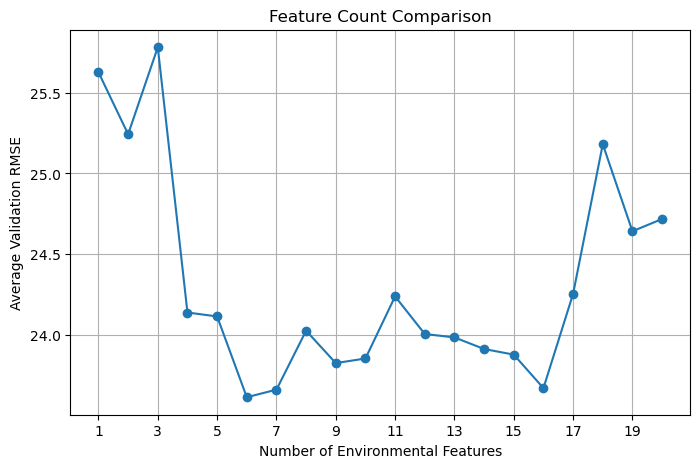

In [206]:
plt.figure(figsize=(8, 5))

plt.plot(average_rmse.index, average_rmse.values, marker="o")

plt.xticks(range(1, 21, 2))
plt.xlabel("Number of Environmental Features")
plt.ylabel("Average Validation RMSE")
plt.title("Feature Count Comparison")
plt.grid(True)

plt.show()

# Final Training From 2000-2020

In [207]:
final_train = df[(df["year"] >= 2000) & (df["year"] <= 2020)].copy()

y_final_train = final_train["Value"]

In [208]:
len(final_train)

20480

In [209]:
final_train["year"].min()

2000

In [210]:
final_train["year"].max()

2020

## Remove Constant Features From Final Training Data

In [211]:
temp_cols = weather_cols + soil_cols

In [212]:
final_variance_filter = VarianceThreshold(threshold=0.0)
final_variance_filter.fit(final_train[temp_cols])

,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0


In [213]:
final_environment_cols = final_variance_filter.get_feature_names_out().tolist()

In [214]:
for col in temp_cols:
    if col not in final_environment_cols:
        print(f"Removed: {col}")

Removed: swe_mean_kg_m2_m07
Removed: swe_mean_kg_m2_m08
Removed: swe_mean_kg_m2_m09


In [215]:
len(final_environment_cols)

90

## Final Pearson Feature Selection

In [216]:
final_pearson = final_train[final_environment_cols].corrwith(y_final_train, method='pearson')
final_pearson_results = final_pearson.to_frame(name='Pearson')

final_pearson_results['Pearson_abs'] = final_pearson.abs().to_frame()

final_pearson_results = final_pearson_results.sort_values('Pearson_abs', ascending=False)

final_top_pearson = final_pearson_results.head(best_feature_count)
final_top_pearson

,Pearson,Pearson_abs
tmax_mean_c_m07,-0.312787,0.312787
available_water_storage_cm_0_100cm,0.298081,0.298081
radiation_total_mj_m2_m06,-0.295676,0.295676
tmax_mean_c_m08,-0.285611,0.285611
prcp_total_mm_m07,0.250252,0.250252
prcp_total_mm_m06,0.224031,0.224031


In [217]:
final_pearson_top_cols = final_top_pearson.index.tolist()
final_pearson_top_cols

['tmax_mean_c_m07',
 'available_water_storage_cm_0_100cm',
 'radiation_total_mj_m2_m06',
 'tmax_mean_c_m08',
 'prcp_total_mm_m07',
 'prcp_total_mm_m06']

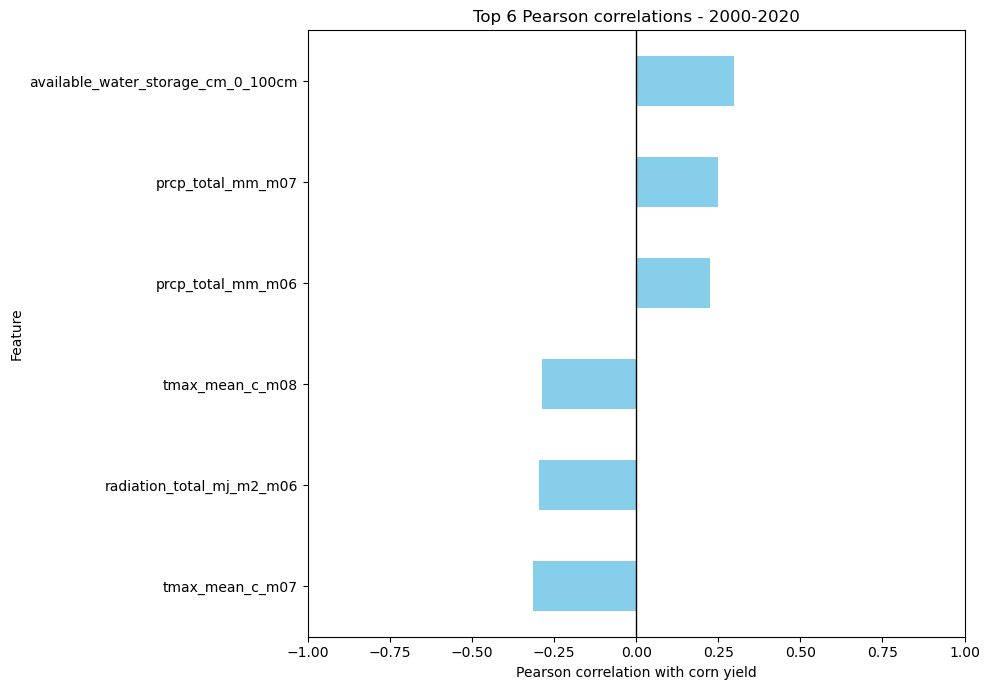

In [218]:
final_top_pearson['Pearson'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1,1)
plt.xlabel("Pearson correlation with corn yield")
plt.ylabel("Feature")
plt.title(f"Top {best_feature_count} Pearson correlations - 2000-2020")
plt.tight_layout()
plt.show()

## Final Spearman Feature Selection

In [219]:
final_spearman = final_train[final_environment_cols].corrwith(y_final_train, method='spearman')
final_spearman_results = final_spearman.to_frame(name='Spearman')

final_spearman_results['Spearman_abs'] = final_spearman.abs().to_frame()

final_spearman_results = final_spearman_results.sort_values('Spearman_abs', ascending=False)

final_top_spearman = final_spearman_results.head(best_feature_count)
final_top_spearman

,Spearman,Spearman_abs
available_water_storage_cm_0_100cm,0.332756,0.332756
tmax_mean_c_m08,-0.279351,0.279351
tmax_mean_c_m07,-0.266988,0.266988
prcp_total_mm_m07,0.253974,0.253974
radiation_total_mj_m2_m06,-0.242167,0.242167
prcp_total_mm_m06,0.233184,0.233184


In [220]:
final_spearman_top_cols = final_top_spearman.index.tolist()
final_spearman_top_cols

['available_water_storage_cm_0_100cm',
 'tmax_mean_c_m08',
 'tmax_mean_c_m07',
 'prcp_total_mm_m07',
 'radiation_total_mj_m2_m06',
 'prcp_total_mm_m06']

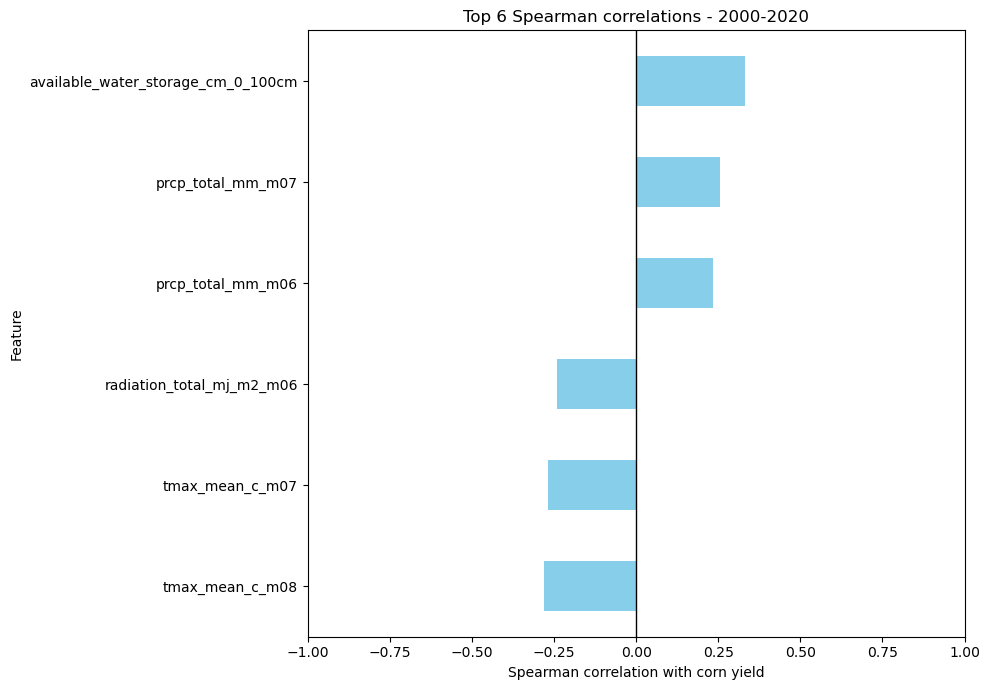

In [221]:
final_top_spearman['Spearman'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(-1,1)
plt.xlabel("Spearman correlation with corn yield")
plt.ylabel("Feature")
plt.title(f"Top {best_feature_count} Spearman correlations - 2000-2020")
plt.tight_layout()
plt.show()

## Final Random Forest Feature Importance

In [222]:
X_final_train = final_train[final_environment_cols]
X_final_train.shape

(20480, 90)

In [223]:
final_forest = RandomForestRegressor(random_state=110, n_jobs=-2)

In [224]:
final_forest.fit(X_final_train, y_final_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [225]:
final_rf_results = pd.DataFrame({"Random Forest": final_forest.feature_importances_},index=X_final_train.columns)

final_rf_results = final_rf_results.sort_values("Random Forest", ascending=False)

final_top_rf = final_rf_results.head(best_feature_count)
final_top_rf

,Random Forest
tmax_mean_c_m07,0.143678
available_water_storage_cm_0_100cm,0.097592
tmin_mean_c_m06,0.090133
tmax_mean_c_m08,0.075839
ksat_um_s_0_30cm,0.046068
vp_mean_pa_m06,0.045691


In [226]:
final_rf_top_cols = final_top_rf.index.tolist()
final_rf_top_cols

['tmax_mean_c_m07',
 'available_water_storage_cm_0_100cm',
 'tmin_mean_c_m06',
 'tmax_mean_c_m08',
 'ksat_um_s_0_30cm',
 'vp_mean_pa_m06']

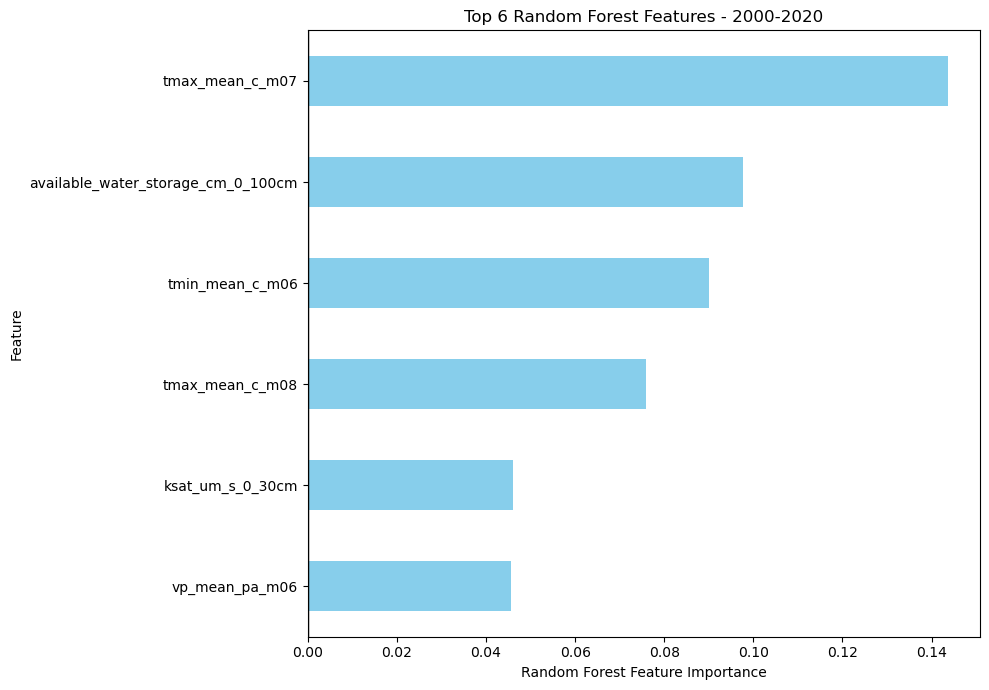

In [227]:
final_top_rf['Random Forest'].sort_values().plot.barh(figsize=(10, 7), color='skyblue')
plt.axvline(0, color="black", linewidth=1)
plt.xlim(left=0)
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title(f"Top {best_feature_count} Random Forest Features - 2000-2020")
plt.tight_layout()
plt.show()

# Preparing Final Prediction Inputs

For the datasets with the different features selected by the correlations and feature importance, I want to use all of the variables I can. This includes the year, latitude, and longitude which will give context to our prediction models.

In [228]:
final_all_input_cols = context_cols + final_environment_cols
final_pearson_input_cols = context_cols + sorted(final_pearson_top_cols)
final_spearman_input_cols = context_cols + sorted(final_spearman_top_cols)
final_rf_input_cols = context_cols + sorted(final_rf_top_cols)

print("All features:", len(final_all_input_cols))
print("Pearson-selected:", len(final_pearson_input_cols))
print("Spearman-selected:", len(final_spearman_input_cols))
print("RF-selected:", len(final_rf_input_cols))

All features: 93
Pearson-selected: 9
Spearman-selected: 9
RF-selected: 9


In [229]:
# All environmental features plus context
X_final_train_all = final_train[final_all_input_cols].copy()
X_final_test_all = test[final_all_input_cols].copy()

In [230]:
# Pearson selected features plus context
X_final_train_pearson = final_train[final_pearson_input_cols].copy()
X_final_test_pearson = test[final_pearson_input_cols].copy()

In [231]:
# Spearman selected features plus context
X_final_train_spearman = final_train[final_spearman_input_cols].copy()
X_final_test_spearman = test[final_spearman_input_cols].copy()

In [232]:
# Random Forest selected features plus context
X_final_train_rf = final_train[final_rf_input_cols].copy()
X_final_test_rf = test[final_rf_input_cols].copy()

In [233]:
# Quick Check
print("Training shape, testing shape")
print("All:", X_final_train_all.shape, X_final_test_all.shape)
print("Pearson:", X_final_train_pearson.shape, X_final_test_pearson.shape)
print("Spearman:", X_final_train_spearman.shape, X_final_test_spearman.shape)
print("Random Forest:", X_final_train_rf.shape, X_final_test_rf.shape)

Training shape, testing shape
All: (20480, 93) (4164, 93)
Pearson: (20480, 9) (4164, 9)
Spearman: (20480, 9) (4164, 9)
Random Forest: (20480, 9) (4164, 9)


# Final Baseline Prediction

In [234]:
# Calculate each county's average yield using training data
final_county_mean_yield = final_train.groupby("fips")["Value"].mean()
final_county_mean_yield.head()

fips
17001    160.723810
17003    151.500000
17005    140.344444
17007    171.035000
17009    156.385000
Name: Value, dtype: float64

In [235]:
final_baseline_predictions = test["fips"].map(final_county_mean_yield)
final_baseline_predictions.head()

0    181.385714
1    181.385714
2    181.385714
3    181.385714
4    181.385714
Name: fips, dtype: float64

In [236]:
final_baseline_predictions.isna().sum()

6

In [237]:
# Calculate state averages using training data
final_state_mean_yield = final_train.groupby("state_alpha")["Value"].mean()
final_state_mean_yield

state_alpha
IA    169.206878
IL    162.081105
IN    155.599663
KS    119.286979
KY    134.186528
MI    130.453120
MN    154.764062
MO    129.324880
ND    103.224526
NE    157.446806
OH    146.791820
SD    114.443106
WI    141.313013
Name: Value, dtype: float64

In [238]:
final_state_baseline_predictions = test["state_alpha"].map(final_state_mean_yield)
final_baseline_predictions = final_baseline_predictions.fillna(final_state_baseline_predictions)

In [239]:
# Use the overall training average if a prediction is still missing
final_overall_mean_yield = final_train["Value"].mean()
final_baseline_predictions = final_baseline_predictions.fillna(final_overall_mean_yield)

In [240]:
print("Testing observations:", len(test))
print("Baseline predictions:", len(final_baseline_predictions))
print("Missing predictions:", final_baseline_predictions.isna().sum())

Testing observations: 4164
Baseline predictions: 4164
Missing predictions: 0


## Evaluate Final Baseline model

In [241]:
# Calculate errors
final_baseline_errors = y_test - final_baseline_predictions
final_baseline_errors

0        44.514286
1        59.414286
2        42.114286
3        43.714286
4        22.114286
           ...    
24618    49.961905
24619    33.461905
24620    26.461905
24621    35.161905
24622    38.461905
Length: 4164, dtype: float64

In [242]:
# calculate Mean Absolute Error
final_baseline_mae = final_baseline_errors.abs().mean()
final_baseline_mae

31.920005963440627

In [243]:
# Calcualte  Mean Squared Error
final_baseline_mse = (final_baseline_errors ** 2).mean()
final_baseline_mse

1276.2439208571664

In [244]:
# Calcualte Root Mean Squared Error
final_baseline_rmse = np.sqrt(final_baseline_mse)
final_baseline_rmse

35.7245562723621

In [245]:
# Calculate R^2
final_baseline_squared_error = (final_baseline_errors ** 2).sum()
test_squared_variation = ((y_test - y_test.mean()) ** 2).sum()
final_baseline_r2 = 1 - (final_baseline_squared_error / test_squared_variation)
final_baseline_r2

0.08325164971775922

In [246]:
final_baseline_results = pd.DataFrame({
    "Model": ["Historical County Average Baseline"],
    "MAE": [final_baseline_mae],
    "MSE": [final_baseline_mse],
    "RMSE": [final_baseline_rmse],
    "R2": [final_baseline_r2]
})

final_baseline_results

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252


# Final Random Forest

## Final Random Forest Prediction With All Features

In [247]:
print("Training inputs:", X_final_train_all.shape)
print("Testing inputs:", X_final_test_all.shape)

Training inputs: (20480, 93)
Testing inputs: (4164, 93)


In [248]:
# Create Model
final_rf_all = RandomForestRegressor(random_state=110, n_jobs=-2)

In [249]:
# Train model
final_rf_all.fit(X_final_train_all, y_final_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [250]:
# Predictions
final_rf_all_predictions = final_rf_all.predict(X_final_test_all)

In [251]:
final_rf_all_predictions

array([200.996, 205.072, 201.51 , ..., 161.062, 167.679, 162.842])

In [252]:
# turn this into a dataframe

In [253]:
final_rf_all_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_rf_all_predictions
}, index=X_final_test_all.index)

final_rf_all_preview.head()

,Actual yield,Predicted yield
0,225.9,200.996
1,240.8,205.072
2,223.5,201.510
3,225.1,206.276
4,203.5,192.205


In [254]:
len(y_test)

4164

In [255]:
len(final_rf_all_predictions)

4164

### Evaluate Random Forest Model

In [256]:
final_rf_all_errors = (final_rf_all_preview["Actual yield"] - final_rf_all_preview["Predicted yield"])
final_rf_all_errors.head()

0    24.904
1    35.728
2    21.990
3    18.824
4    11.295
dtype: float64

In [257]:
final_rf_all_mae = final_rf_all_errors.abs().mean()
final_rf_all_mse = (final_rf_all_errors ** 2).mean()
final_rf_all_rmse = np.sqrt(final_rf_all_mse)
final_rf_all_squared_error = (final_rf_all_errors ** 2).sum()
final_rf_all_r2 = 1 - (final_rf_all_squared_error / test_squared_variation)

In [258]:
final_rf_all_results = pd.DataFrame({
    "Model": ["Random Forest All Features"],
    "MAE": [final_rf_all_mae],
    "MSE": [final_rf_all_mse],
    "RMSE": [final_rf_all_rmse],
    "R2": [final_rf_all_r2]
})

final_rf_all_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest All Features,20.003242,594.062994,24.373408,0.573274


In [259]:
final_model_comparison = pd.concat([final_baseline_results, final_rf_all_results], ignore_index=True)
final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274


## Final Random Forest Prediction With Pearson Correlation Selected Features

In [260]:
print("Training inputs:", X_final_train_pearson.shape)
print("Testing inputs:", X_final_test_pearson.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [261]:
# Create Model
final_rf_pearson = RandomForestRegressor(random_state=110, n_jobs=-2)

In [262]:
# Train model
final_rf_pearson.fit(X_final_train_pearson, y_final_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [263]:
# Predictions
final_rf_pearson_predictions = final_rf_pearson.predict(X_final_test_pearson)

In [264]:
final_rf_pearson_predictions

array([195.302, 197.852, 201.11 , ..., 165.506, 172.307, 167.02 ])

In [265]:
final_rf_pearson_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_rf_pearson_predictions
}, index=X_final_test_pearson.index)

final_rf_pearson_preview.head()

,Actual yield,Predicted yield
0,225.9,195.302
1,240.8,197.852
2,223.5,201.110
3,225.1,199.353
4,203.5,206.929


In [266]:
len(final_rf_pearson_predictions)

4164

### Evaluate Random Forest Model

In [267]:
final_rf_pearson_errors = (final_rf_pearson_preview["Actual yield"] - final_rf_pearson_preview["Predicted yield"])
final_rf_pearson_errors.head()

0    30.598
1    42.948
2    22.390
3    25.747
4    -3.429
dtype: float64

In [268]:
final_rf_pearson_mae = final_rf_pearson_errors.abs().mean()
final_rf_pearson_mse = (final_rf_pearson_errors ** 2).mean()
final_rf_pearson_rmse = np.sqrt(final_rf_pearson_mse)
final_rf_pearson_squared_error = (final_rf_pearson_errors ** 2).sum()
final_rf_pearson_r2 = 1 - (final_rf_pearson_squared_error / test_squared_variation)

In [269]:
final_rf_pearson_results = pd.DataFrame({
    "Model": ["Random Forest Pearson Features"],
    "MAE": [final_rf_pearson_mae],
    "MSE": [final_rf_pearson_mse],
    "RMSE": [final_rf_pearson_rmse],
    "R2": [final_rf_pearson_r2]
})

final_rf_pearson_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Pearson Features,18.149201,495.3799,22.257131,0.64416


In [270]:
final_model_comparison = pd.concat([final_baseline_results, final_rf_all_results, final_rf_pearson_results], ignore_index=True)
final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160


## Final Random Forest Prediction With Spearman Correlation Selected Features

In [271]:
print("Training inputs:", X_final_train_spearman.shape)
print("Testing inputs:", X_final_test_spearman.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [272]:
# Create Model
final_rf_spearman = RandomForestRegressor(random_state=110, n_jobs=-2)

In [273]:
# Train model
final_rf_spearman.fit(X_final_train_spearman, y_final_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [274]:
# Predictions
final_rf_spearman_predictions = final_rf_spearman.predict(X_final_test_spearman)

In [275]:
final_rf_spearman_predictions

array([195.302, 197.852, 201.11 , ..., 165.506, 172.307, 167.02 ])

In [276]:
final_rf_spearman_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_rf_spearman_predictions
}, index=X_final_test_spearman.index)

final_rf_spearman_preview.head()

,Actual yield,Predicted yield
0,225.9,195.302
1,240.8,197.852
2,223.5,201.110
3,225.1,199.353
4,203.5,206.929


In [277]:
len(final_rf_spearman_predictions)

4164

### Evaluate Random Forest Model

In [278]:
final_rf_spearman_errors = (final_rf_spearman_preview["Actual yield"] - final_rf_spearman_preview["Predicted yield"])
final_rf_spearman_errors.head()

0    30.598
1    42.948
2    22.390
3    25.747
4    -3.429
dtype: float64

In [279]:
final_rf_spearman_mae = final_rf_spearman_errors.abs().mean()
final_rf_spearman_mse = (final_rf_spearman_errors ** 2).mean()
final_rf_spearman_rmse = np.sqrt(final_rf_spearman_mse)
final_rf_spearman_squared_error = (final_rf_spearman_errors ** 2).sum()
final_rf_spearman_r2 = 1 - (final_rf_spearman_squared_error / test_squared_variation)

In [280]:
final_rf_spearman_results = pd.DataFrame({
    "Model": ["Random Forest Spearman Features"],
    "MAE": [final_rf_spearman_mae],
    "MSE": [final_rf_spearman_mse],
    "RMSE": [final_rf_spearman_rmse],
    "R2": [final_rf_spearman_r2]
})

final_rf_spearman_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Spearman Features,18.149201,495.3799,22.257131,0.64416


In [281]:
final_model_comparison = pd.concat([final_baseline_results, final_rf_all_results, final_rf_pearson_results, final_rf_spearman_results], ignore_index=True)
final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160


## Final Random Forest Prediction With RF Feature Importance Selected Features

In [282]:
print("Training inputs:", X_final_train_rf.shape)
print("Testings inputs:", X_final_test_rf.shape)

Training inputs: (20480, 9)
Testings inputs: (4164, 9)


In [283]:
# Create Model
final_rf_selected = RandomForestRegressor(random_state=110, n_jobs=-2)

In [284]:
# Train model
final_rf_selected.fit(X_final_train_rf, y_final_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [285]:
# Predictions
final_rf_selected_predictions = final_rf_selected.predict(X_final_test_rf)

In [286]:
final_rf_selected_predictions

array([201.514, 202.173, 194.298, ..., 163.443, 160.905, 167.914])

In [287]:
final_rf_selected_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_rf_selected_predictions
}, index=X_final_test_rf.index)

final_rf_selected_preview.head()

,Actual yield,Predicted yield
0,225.9,201.514
1,240.8,202.173
2,223.5,194.298
3,225.1,199.320
4,203.5,205.955


In [288]:
len(final_rf_selected_predictions)

4164

### Evaluate Random Forest Model

In [289]:
final_rf_selected_errors = (final_rf_selected_preview["Actual yield"] - final_rf_selected_preview["Predicted yield"])
final_rf_selected_errors.head()

0    24.386
1    38.627
2    29.202
3    25.780
4    -2.455
dtype: float64

In [290]:
final_rf_selected_mae = final_rf_selected_errors.abs().mean()
final_rf_selected_mse = (final_rf_selected_errors ** 2).mean()
final_rf_selected_rmse = np.sqrt(final_rf_selected_mse)
final_rf_selected_squared_error = (final_rf_selected_errors ** 2).sum()
final_rf_selected_r2 = 1 - (final_rf_selected_squared_error / test_squared_variation)

In [291]:
final_rf_selected_results = pd.DataFrame({
    "Model": ["Random Forest Selected Features"],
    "MAE": [final_rf_selected_mae],
    "MSE": [final_rf_selected_mse],
    "RMSE": [final_rf_selected_rmse],
    "R2": [final_rf_selected_r2]
})

final_rf_selected_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Selected Features,18.32173,512.407569,22.636421,0.631929


In [292]:
final_model_comparison = pd.concat([final_baseline_results, final_rf_all_results, final_rf_pearson_results, final_rf_spearman_results, final_rf_selected_results], ignore_index=True)
final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929


# Final Linear Regression

## Final Linear Regression Prediction With All Features

In [293]:
print("Training inputs:", X_final_train_all.shape)
print("Testing inputs:", X_final_test_all.shape)

Training inputs: (20480, 93)
Testing inputs: (4164, 93)


In [294]:
# Scale the predictors
final_scaler_all = StandardScaler()

X_final_train_all_scaled = final_scaler_all.fit_transform(X_final_train_all)
X_final_test_all_scaled = final_scaler_all.transform(X_final_test_all)

In [295]:
# Create Model
final_lr_all = LinearRegression()

In [296]:
# Train Model
final_lr_all.fit(X_final_train_all_scaled, y_final_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [297]:
# Predictions
final_lr_all_predictions = final_lr_all.predict(X_final_test_all_scaled)

In [298]:
final_lr_all_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_lr_all_predictions
}, index=X_final_test_all.index)

final_lr_all_preview.head()

,Actual yield,Predicted yield
0,225.9,210.164539
1,240.8,222.705964
2,223.5,190.015068
3,225.1,202.392512
4,203.5,192.112986


In [299]:
len(final_lr_all_predictions)

4164

### Evaluate Linear Regression Model

In [300]:
final_lr_all_errors = (final_lr_all_preview["Actual yield"] - final_lr_all_preview["Predicted yield"])
final_lr_all_errors.head()

0    15.735461
1    18.094036
2    33.484932
3    22.707488
4    11.387014
dtype: float64

In [301]:
final_lr_all_mae = final_lr_all_errors.abs().mean()
final_lr_all_mse = (final_lr_all_errors ** 2).mean()
final_lr_all_rmse = np.sqrt(final_lr_all_mse)
final_lr_all_squared_error = (final_lr_all_errors ** 2).sum()
final_lr_all_r2 = 1 - (final_lr_all_squared_error / test_squared_variation)

In [302]:
final_lr_all_results = pd.DataFrame({
    "Model": ["Linear Regression All Features"],
    "MAE": [final_lr_all_mae],
    "MSE": [final_lr_all_mse],
    "RMSE": [final_lr_all_rmse],
    "R2": [final_lr_all_r2]
})

final_lr_all_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683


In [303]:
final_model_comparison = pd.concat([final_baseline_results, final_rf_all_results, final_rf_pearson_results, final_rf_spearman_results, final_rf_selected_results, final_lr_all_results], ignore_index=True)
final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683


## Final Linear Regression Prediction With Pearson Correlation Selected Features

In [304]:
print("Training inputs:", X_final_train_pearson.shape)
print("Testing inputs:", X_final_test_pearson.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [305]:
# Scale the predictors
final_scaler_pearson = StandardScaler()

X_final_train_pearson_scaled = final_scaler_pearson.fit_transform(X_final_train_pearson)
X_final_test_pearson_scaled = final_scaler_pearson.transform(X_final_test_pearson)

In [306]:
# Create Model
final_lr_pearson = LinearRegression()

In [307]:
# Train Model
final_lr_pearson.fit(X_final_train_pearson_scaled, y_final_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [308]:
# Predictions
final_lr_pearson_predictions = final_lr_pearson.predict(X_final_test_pearson_scaled)

In [309]:
final_lr_pearson_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_lr_pearson_predictions
}, index=X_final_test_pearson.index)

final_lr_pearson_preview.head()

,Actual yield,Predicted yield
0,225.9,193.292496
1,240.8,197.692107
2,223.5,183.637854
3,225.1,185.585902
4,203.5,181.550206


In [310]:
len(final_lr_pearson_predictions)

4164

### Evaluate Linear Regression Model

In [311]:
final_lr_pearson_errors = (final_lr_pearson_preview["Actual yield"] - final_lr_pearson_preview["Predicted yield"])
final_lr_pearson_errors.head()

0    32.607504
1    43.107893
2    39.862146
3    39.514098
4    21.949794
dtype: float64

In [312]:
final_lr_pearson_mae = final_lr_pearson_errors.abs().mean()
final_lr_pearson_mse = (final_lr_pearson_errors ** 2).mean()
final_lr_pearson_rmse = np.sqrt(final_lr_pearson_mse)
final_lr_pearson_squared_error = (final_lr_pearson_errors ** 2).sum()
final_lr_pearson_r2 = 1 - (final_lr_pearson_squared_error / test_squared_variation)

In [313]:
final_lr_pearson_results = pd.DataFrame({
    "Model": ["Linear Regression Pearson Features"],
    "MAE": [final_lr_pearson_mae],
    "MSE": [final_lr_pearson_mse],
    "RMSE": [final_lr_pearson_rmse],
    "R2": [final_lr_pearson_r2]
})

final_lr_pearson_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893


In [314]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results,
    final_rf_pearson_results,
    final_rf_spearman_results,
    final_rf_selected_results,
    final_lr_all_results,
    final_lr_pearson_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893


## Final Linear Regression Prediction With Spearman Correlation Selected Features

In [315]:
print("Training inputs:", X_final_train_spearman.shape)
print("Testing inputs:", X_final_test_spearman.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [316]:
# Scale the predictors
final_scaler_spearman = StandardScaler()

X_final_train_spearman_scaled = final_scaler_spearman.fit_transform(X_final_train_spearman)
X_final_test_spearman_scaled = final_scaler_spearman.transform(X_final_test_spearman)

In [317]:
# Create Model
final_lr_spearman = LinearRegression()

In [318]:
# Train Model
final_lr_spearman.fit(X_final_train_spearman_scaled, y_final_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [319]:
# Predictions
final_lr_spearman_predictions = final_lr_spearman.predict(X_final_test_spearman_scaled)

In [320]:
final_lr_spearman_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_lr_spearman_predictions
}, index=X_final_test_spearman.index)

final_lr_spearman_preview.head()

,Actual yield,Predicted yield
0,225.9,193.292496
1,240.8,197.692107
2,223.5,183.637854
3,225.1,185.585902
4,203.5,181.550206


In [321]:
len(final_lr_spearman_predictions)

4164

### Evaluate Linear Regression Model

In [322]:
final_lr_spearman_errors = (final_lr_spearman_preview["Actual yield"] - final_lr_spearman_preview["Predicted yield"])
final_lr_spearman_errors.head()

0    32.607504
1    43.107893
2    39.862146
3    39.514098
4    21.949794
dtype: float64

In [323]:
final_lr_spearman_mae = final_lr_spearman_errors.abs().mean()
final_lr_spearman_mse = (final_lr_spearman_errors ** 2).mean()
final_lr_spearman_rmse = np.sqrt(final_lr_spearman_mse)
final_lr_spearman_squared_error = (final_lr_spearman_errors ** 2).sum()
final_lr_spearman_r2 = 1 - (final_lr_spearman_squared_error / test_squared_variation)

In [324]:
final_lr_spearman_results = pd.DataFrame({
    "Model": ["Linear Regression Spearman Features"],
    "MAE": [final_lr_spearman_mae],
    "MSE": [final_lr_spearman_mse],
    "RMSE": [final_lr_spearman_rmse],
    "R2": [final_lr_spearman_r2]
})

final_lr_spearman_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893


In [325]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results,
    final_rf_pearson_results,
    final_rf_spearman_results,
    final_rf_selected_results,
    final_lr_all_results,
    final_lr_pearson_results,
    final_lr_spearman_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893
7,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893


## Final Linear Regression Prediction With RF Feature Importance Selected Features

In [326]:
print("Training inputs:", X_final_train_rf.shape)
print("Testing inputs:", X_final_test_rf.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [327]:
# Scale the predictors
final_scaler_rf = StandardScaler()

X_final_train_rf_scaled = final_scaler_rf.fit_transform(X_final_train_rf)
X_final_test_rf_scaled = final_scaler_rf.transform(X_final_test_rf)

In [328]:
# Create Model
final_lr_selected = LinearRegression()

In [329]:
# Train Model
final_lr_selected.fit(X_final_train_rf_scaled, y_final_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [330]:
# Predictions
final_lr_selected_predictions = final_lr_selected.predict(X_final_test_rf_scaled)

In [331]:
final_lr_selected_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_lr_selected_predictions
}, index=X_final_test_rf.index)

final_lr_selected_preview.head()

,Actual yield,Predicted yield
0,225.9,190.097601
1,240.8,197.521111
2,223.5,178.898214
3,225.1,188.645059
4,203.5,185.753443


In [332]:
len(final_lr_selected_predictions)

4164

### Evaluate Linear Regression Model

In [333]:
final_lr_selected_errors = (final_lr_selected_preview["Actual yield"] - final_lr_selected_preview["Predicted yield"])
final_lr_selected_errors.head()

0    35.802399
1    43.278889
2    44.601786
3    36.454941
4    17.746557
dtype: float64

In [334]:
final_lr_selected_mae = final_lr_selected_errors.abs().mean()
final_lr_selected_mse = (final_lr_selected_errors ** 2).mean()
final_lr_selected_rmse = np.sqrt(final_lr_selected_mse)
final_lr_selected_squared_error = (final_lr_selected_errors ** 2).sum()
final_lr_selected_r2 = 1 - (final_lr_selected_squared_error / test_squared_variation)

In [335]:
final_lr_selected_results = pd.DataFrame({
    "Model": ["Linear Regression RF Selected Features"],
    "MAE": [final_lr_selected_mae],
    "MSE": [final_lr_selected_mse],
    "RMSE": [final_lr_selected_rmse],
    "R2": [final_lr_selected_r2]
})

final_lr_selected_results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression RF Selected Features,24.078489,922.147451,30.366881,0.337605


In [336]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results,
    final_rf_pearson_results,
    final_rf_spearman_results,
    final_rf_selected_results,
    final_lr_all_results,
    final_lr_pearson_results,
    final_lr_spearman_results,
    final_lr_selected_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893
7,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893
8,Linear Regression RF Selected Features,24.078489,922.147451,30.366881,0.337605


# Final Neural Network

[https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html)

## Final Neural Network Prediction With All Features

In [337]:
print("Training inputs:", X_final_train_all_scaled.shape)
print("Testing inputs:", X_final_test_all_scaled.shape)

Training inputs: (20480, 93)
Testing inputs: (4164, 93)


In [338]:
# Create Model
final_nn_all = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [339]:
# Train Model
final_nn_all.fit(X_final_train_all_scaled, y_final_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [340]:
# How many epochs?
final_nn_all.n_iter_

684

In [341]:
# Predictions
final_nn_all_predictions = final_nn_all.predict(X_final_test_all_scaled)

In [342]:
final_nn_all_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_nn_all_predictions
}, index=X_final_test_all.index)

final_nn_all_preview.head()

,Actual yield,Predicted yield
0,225.9,244.339261
1,240.8,243.606185
2,223.5,225.483083
3,225.1,227.985232
4,203.5,208.676596


In [343]:
len(final_nn_all_predictions)

4164

### Evaluate Neural Network Model

In [344]:
final_nn_all_errors = (final_nn_all_preview["Actual yield"] - final_nn_all_preview["Predicted yield"])
final_nn_all_errors.head()

0   -18.439261
1    -2.806185
2    -1.983083
3    -2.885232
4    -5.176596
dtype: float64

In [345]:
final_nn_all_mae = final_nn_all_errors.abs().mean()
final_nn_all_mse = (final_nn_all_errors ** 2).mean()
final_nn_all_rmse = np.sqrt(final_nn_all_mse)
final_nn_all_squared_error = (final_nn_all_errors ** 2).sum()
final_nn_all_r2 = 1 - (final_nn_all_squared_error / test_squared_variation)

In [346]:
final_nn_all_results = pd.DataFrame({
    "Model": ["Neural Network All Features"],
    "MAE": [final_nn_all_mae],
    "MSE": [final_nn_all_mse],
    "RMSE": [final_nn_all_rmse],
    "R2": [final_nn_all_r2]
})

final_nn_all_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network All Features,19.705053,614.370524,24.786499,0.558687


In [347]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results, 
    final_rf_pearson_results, 
    final_rf_spearman_results, 
    final_rf_selected_results, 
    final_lr_all_results, 
    final_lr_pearson_results,
    final_lr_spearman_results,
    final_lr_selected_results,
    final_nn_all_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893
7,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893
8,Linear Regression RF Selected Features,24.078489,922.147451,30.366881,0.337605
9,Neural Network All Features,19.705053,614.370524,24.786499,0.558687


## Final Neural Network Prediction With Pearson Correlation Selected Features

In [348]:
print("Training inputs:", X_final_train_pearson_scaled.shape)
print("Testing inputs:", X_final_test_pearson_scaled.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [349]:
# Create Model
final_nn_pearson = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [350]:
# Train Model
final_nn_pearson.fit(X_final_train_pearson_scaled, y_final_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [351]:
# How many epochs?
final_nn_pearson.n_iter_

935

In [352]:
# Predictions
final_nn_pearson_predictions = final_nn_pearson.predict(X_final_test_pearson_scaled)

In [353]:
final_nn_pearson_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_nn_pearson_predictions
}, index=X_final_test_pearson.index)

final_nn_pearson_preview.head()

,Actual yield,Predicted yield
0,225.9,211.043072
1,240.8,215.406699
2,223.5,208.388313
3,225.1,207.033967
4,203.5,215.255996


In [354]:
len(final_nn_pearson_predictions)

4164

### Evaluate Neural Network Model

In [355]:
final_nn_pearson_errors = (final_nn_pearson_preview["Actual yield"] - final_nn_pearson_preview["Predicted yield"])
final_nn_pearson_errors.head()

0    14.856928
1    25.393301
2    15.111687
3    18.066033
4   -11.755996
dtype: float64

In [356]:
final_nn_pearson_mae = final_nn_pearson_errors.abs().mean()
final_nn_pearson_mse = (final_nn_pearson_errors ** 2).mean()
final_nn_pearson_rmse = np.sqrt(final_nn_pearson_mse)
final_nn_pearson_squared_error = (final_nn_pearson_errors ** 2).sum()
final_nn_pearson_r2 = 1 - (final_nn_pearson_squared_error / test_squared_variation)

In [357]:
final_nn_pearson_results = pd.DataFrame({
    "Model": ["Neural Network Pearson Features"],
    "MAE": [final_nn_pearson_mae],
    "MSE": [final_nn_pearson_mse],
    "RMSE": [final_nn_pearson_rmse],
    "R2": [final_nn_pearson_r2]
})

final_nn_pearson_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network Pearson Features,17.168607,528.202541,22.982657,0.620583


In [358]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results, 
    final_rf_pearson_results, 
    final_rf_spearman_results, 
    final_rf_selected_results, 
    final_lr_all_results, 
    final_lr_pearson_results,
    final_lr_spearman_results,
    final_lr_selected_results,
    final_nn_all_results,
    final_nn_pearson_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893
7,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893
8,Linear Regression RF Selected Features,24.078489,922.147451,30.366881,0.337605
9,Neural Network All Features,19.705053,614.370524,24.786499,0.558687


## Final Neural Network Prediction With Spearman Correlation Selected Features

In [359]:
print("Training inputs:", X_final_train_spearman_scaled.shape)
print("Testing inputs:", X_final_test_spearman_scaled.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [360]:
# Create Model
final_nn_spearman = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [361]:
# Train Model
final_nn_spearman.fit(X_final_train_spearman_scaled, y_final_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [362]:
# How many epochs?
final_nn_spearman.n_iter_

935

In [363]:
# Predictions
final_nn_spearman_predictions = final_nn_spearman.predict(X_final_test_spearman_scaled)

In [364]:
final_nn_spearman_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_nn_spearman_predictions
}, index=X_final_test_spearman.index)

final_nn_spearman_preview.head()

,Actual yield,Predicted yield
0,225.9,211.043072
1,240.8,215.406699
2,223.5,208.388313
3,225.1,207.033967
4,203.5,215.255996


In [365]:
len(final_nn_spearman_predictions)

4164

### Evaluate Neural Network Model

In [366]:
final_nn_spearman_errors = (final_nn_spearman_preview["Actual yield"] - final_nn_spearman_preview["Predicted yield"])
final_nn_spearman_errors.head()

0    14.856928
1    25.393301
2    15.111687
3    18.066033
4   -11.755996
dtype: float64

In [367]:
final_nn_spearman_mae = final_nn_spearman_errors.abs().mean()
final_nn_spearman_mse = (final_nn_spearman_errors ** 2).mean()
final_nn_spearman_rmse = np.sqrt(final_nn_spearman_mse)
final_nn_spearman_squared_error = (final_nn_spearman_errors ** 2).sum()
final_nn_spearman_r2 = 1 - (final_nn_spearman_squared_error / test_squared_variation)

In [368]:
final_nn_spearman_results = pd.DataFrame({
    "Model": ["Neural Network Spearman Features"],
    "MAE": [final_nn_spearman_mae],
    "MSE": [final_nn_spearman_mse],
    "RMSE": [final_nn_spearman_rmse],
    "R2": [final_nn_spearman_r2]
})

final_nn_spearman_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network Spearman Features,17.168607,528.202541,22.982657,0.620583


In [369]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results, 
    final_rf_pearson_results, 
    final_rf_spearman_results, 
    final_rf_selected_results, 
    final_lr_all_results, 
    final_lr_pearson_results,
    final_lr_spearman_results,
    final_lr_selected_results,
    final_nn_all_results,
    final_nn_pearson_results,
    final_nn_spearman_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893
7,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893
8,Linear Regression RF Selected Features,24.078489,922.147451,30.366881,0.337605
9,Neural Network All Features,19.705053,614.370524,24.786499,0.558687


## Final Neural Network Prediction With RF Feature Importance Selected Features

In [370]:
print("Training inputs:", X_final_train_rf_scaled.shape)
print("Testing inputs:", X_final_test_rf_scaled.shape)

Training inputs: (20480, 9)
Testing inputs: (4164, 9)


In [371]:
# Create Model
final_nn_selected = MLPRegressor(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=2000,
    early_stopping=False,
    random_state=110
)

In [372]:
# Train Model
final_nn_selected.fit(X_final_train_rf_scaled, y_final_train)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [373]:
# How many epochs?
final_nn_selected.n_iter_

868

In [374]:
# Predictions
final_nn_selected_predictions = final_nn_selected.predict(X_final_test_rf_scaled)

In [375]:
final_nn_selected_preview = pd.DataFrame({
    "Actual yield": y_test,
    "Predicted yield": final_nn_selected_predictions
}, index=X_final_test_rf.index)

final_nn_selected_preview.head()

,Actual yield,Predicted yield
0,225.9,229.114299
1,240.8,228.990265
2,223.5,198.846051
3,225.1,215.625908
4,203.5,226.639637


In [376]:
len(final_nn_selected_predictions)

4164

### Evaluate Neural Network Model

In [377]:
final_nn_selected_errors = (final_nn_selected_preview["Actual yield"] - final_nn_selected_preview["Predicted yield"])
final_nn_selected_errors.head()

0    -3.214299
1    11.809735
2    24.653949
3     9.474092
4   -23.139637
dtype: float64

In [378]:
final_nn_selected_mae = final_nn_selected_errors.abs().mean()
final_nn_selected_mse = (final_nn_selected_errors ** 2).mean()
final_nn_selected_rmse = np.sqrt(final_nn_selected_mse)
final_nn_selected_squared_error = (final_nn_selected_errors ** 2).sum()
final_nn_selected_r2 = 1 - (final_nn_selected_squared_error / test_squared_variation)

In [379]:
final_nn_selected_results = pd.DataFrame({
    "Model": ["Neural Network RF Selected Features"],
    "MAE": [final_nn_selected_mae],
    "MSE": [final_nn_selected_mse],
    "RMSE": [final_nn_selected_rmse],
    "R2": [final_nn_selected_r2]
})

final_nn_selected_results

,Model,MAE,MSE,RMSE,R2
0,Neural Network RF Selected Features,17.837267,528.189762,22.982379,0.620592


In [380]:
final_model_comparison = pd.concat([
    final_baseline_results,
    final_rf_all_results, 
    final_rf_pearson_results, 
    final_rf_spearman_results, 
    final_rf_selected_results, 
    final_lr_all_results, 
    final_lr_pearson_results,
    final_lr_spearman_results,
    final_lr_selected_results,
    final_nn_all_results,
    final_nn_pearson_results,
    final_nn_spearman_results,
    final_nn_selected_results
], ignore_index=True)

final_model_comparison

,Model,MAE,MSE,RMSE,R2
0,Historical County Average Baseline,31.920006,1276.243921,35.724556,0.083252
1,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
2,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
3,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
4,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
5,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
6,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893
7,Linear Regression Spearman Features,23.722743,912.002332,30.199376,0.344893
8,Linear Regression RF Selected Features,24.078489,922.147451,30.366881,0.337605
9,Neural Network All Features,19.705053,614.370524,24.786499,0.558687


# Final Testing Results Comparison

Models were trained using observations from 2000–2020 and evaluated using observations from 2021–2025.

Lower MAE, MSE, and RMSE indicate better predictions. Higher $R^2$ indicates better performance.

I am sorting the results by RMSE because it expresses prediction error in the original yield units of bushels per acre and gives greater influence to larger prediction errors.

[https://doi.org/10.5194/gmd-15-5481-2022](https://doi.org/10.5194/gmd-15-5481-2022)

In [381]:
final_test_results = final_model_comparison.copy()

final_test_results = final_test_results.sort_values("RMSE").reset_index(drop=True)

final_test_results

,Model,MAE,MSE,RMSE,R2
0,Random Forest Pearson Features,18.149201,495.379900,22.257131,0.644160
1,Random Forest Spearman Features,18.149201,495.379900,22.257131,0.644160
2,Random Forest Selected Features,18.321730,512.407569,22.636421,0.631929
3,Neural Network RF Selected Features,17.837267,528.189762,22.982379,0.620592
4,Neural Network Pearson Features,17.168607,528.202541,22.982657,0.620583
5,Neural Network Spearman Features,17.168607,528.202541,22.982657,0.620583
6,Random Forest All Features,20.003242,594.062994,24.373408,0.573274
7,Neural Network All Features,19.705053,614.370524,24.786499,0.558687
8,Linear Regression All Features,20.271363,690.943579,26.285806,0.503683
9,Linear Regression Pearson Features,23.722743,912.002332,30.199376,0.344893


In [382]:
final_feature_set_comparison = pd.DataFrame({
    "Feature Set": [
        "All Features",
        "Pearson",
        "Spearman",
        "RF Importance"
    ],
    "Random Forest RMSE": [
        final_rf_all_rmse,
        final_rf_pearson_rmse,
        final_rf_spearman_rmse,
        final_rf_selected_rmse
    ],
    "Linear Regression RMSE": [
        final_lr_all_rmse,
        final_lr_pearson_rmse,
        final_lr_spearman_rmse,
        final_lr_selected_rmse
    ],
    "Neural Network RMSE": [
        final_nn_all_rmse,
        final_nn_pearson_rmse,
        final_nn_spearman_rmse,
        final_nn_selected_rmse
    ]
})

final_feature_set_comparison

,Feature Set,Random Forest RMSE,Linear Regression RMSE,Neural Network RMSE
0,All Features,24.373408,26.285806,24.786499
1,Pearson,22.257131,30.199376,22.982657
2,Spearman,22.257131,30.199376,22.982657
3,RF Importance,22.636421,30.366881,22.982379


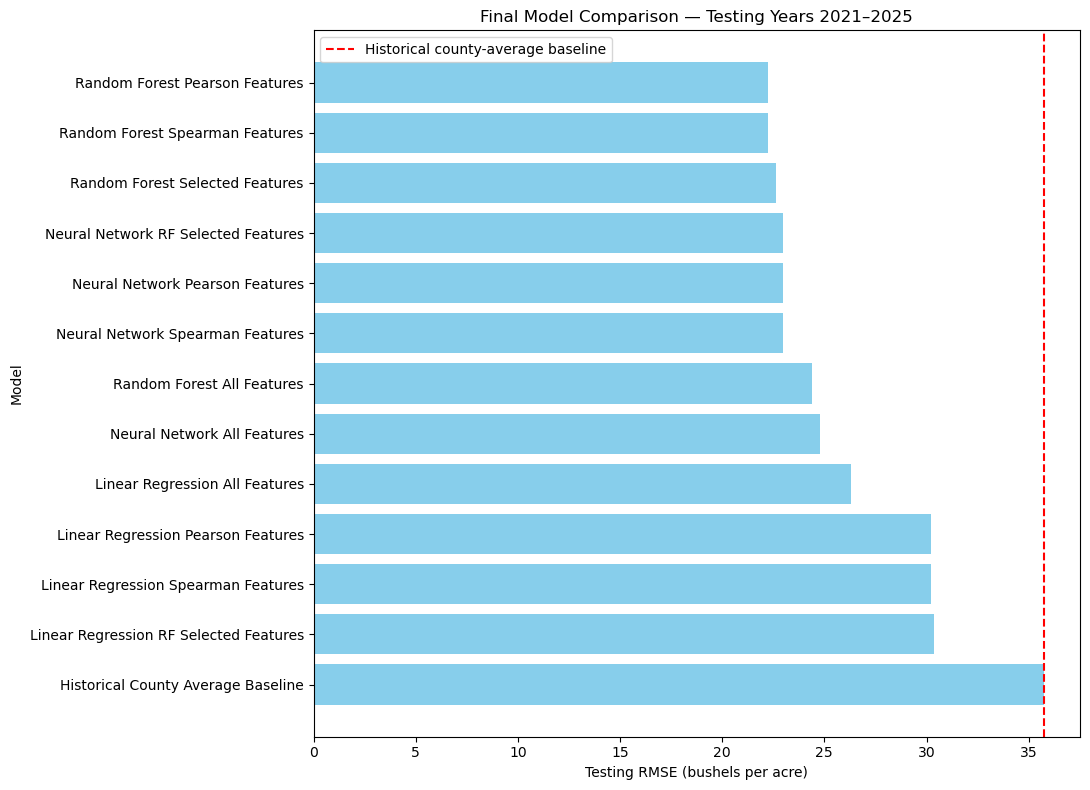

In [383]:
plt.figure(figsize=(11, 8))

plt.barh(final_test_results["Model"], final_test_results["RMSE"], color="skyblue")

plt.gca().invert_yaxis()

plt.axvline(final_baseline_rmse, color="red", linestyle="--", label="Historical county-average baseline")

plt.xlabel("Testing RMSE (bushels per acre)")
plt.ylabel("Model")
plt.title("Final Model Comparison — Testing Years 2021–2025")

plt.legend()
plt.tight_layout()
plt.show()

# Effects of Feature Selection

In [385]:
selected_validation = feature_count_df[feature_count_df["Features"] == best_feature_count]

selected_validation = selected_validation.pivot(
    index="Model",
    columns="Method",
    values="RMSE"
)

selected_validation.round(2)

Method,Pearson,RF Importance,Spearman
Model,,,
Linear Regression,28.18,27.83,28.18
Neural Network,22.66,26.11,22.66
Random Forest,18.63,19.66,18.63


In [386]:
selection_effects = pd.DataFrame({

    "Prediction model": [
        "Random Forest", "Random Forest", "Random Forest",
        "Linear Regression", "Linear Regression", "Linear Regression",
        "Neural Network", "Neural Network", "Neural Network"
    ],

    "Selection method": [
        "Pearson", "Spearman", "RF importance",
        "Pearson", "Spearman", "RF importance",
        "Pearson", "Spearman", "RF importance"
    ],

    "Validation reduction (%)": [
        # Random Forest
        (rf_all_rmse - selected_validation.loc["Random Forest", "Pearson"]) / rf_all_rmse * 100,
        (rf_all_rmse - selected_validation.loc["Random Forest", "Spearman"]) / rf_all_rmse * 100,
        (rf_all_rmse - selected_validation.loc["Random Forest", "RF Importance"]) / rf_all_rmse * 100,

        # Linear Regression
        (lr_all_rmse - selected_validation.loc["Linear Regression", "Pearson"]) / lr_all_rmse * 100,
        (lr_all_rmse - selected_validation.loc["Linear Regression", "Spearman"]) / lr_all_rmse * 100,
        (lr_all_rmse - selected_validation.loc["Linear Regression", "RF Importance"]) / lr_all_rmse * 100,

        # Neural Network
        (nn_all_rmse - selected_validation.loc["Neural Network", "Pearson"]) / nn_all_rmse * 100,
        (nn_all_rmse - selected_validation.loc["Neural Network", "Spearman"]) / nn_all_rmse * 100,
        (nn_all_rmse - selected_validation.loc["Neural Network", "RF Importance"]) / nn_all_rmse * 100
    ],

    "Test reduction (%)": [
        # Random Forest
        (final_rf_all_rmse - final_rf_pearson_rmse) / final_rf_all_rmse * 100,
        (final_rf_all_rmse - final_rf_spearman_rmse) / final_rf_all_rmse * 100,
        (final_rf_all_rmse - final_rf_selected_rmse) / final_rf_all_rmse * 100,

        # Linear Regression
        (final_lr_all_rmse - final_lr_pearson_rmse) / final_lr_all_rmse * 100,
        (final_lr_all_rmse - final_lr_spearman_rmse) / final_lr_all_rmse * 100,
        (final_lr_all_rmse - final_lr_selected_rmse) / final_lr_all_rmse * 100,

        # Neural Network
        (final_nn_all_rmse - final_nn_pearson_rmse) / final_nn_all_rmse * 100,
        (final_nn_all_rmse - final_nn_spearman_rmse) / final_nn_all_rmse * 100,
        (final_nn_all_rmse - final_nn_selected_rmse) / final_nn_all_rmse * 100
    ]
})

selection_effects.round(2)

,Prediction model,Selection method,Validation reduction (%),Test reduction (%)
0,Random Forest,Pearson,15.07,8.68
1,Random Forest,Spearman,15.07,8.68
2,Random Forest,RF importance,10.35,7.13
3,Linear Regression,Pearson,-1.48,-14.89
4,Linear Regression,Spearman,-1.48,-14.89
5,Linear Regression,RF importance,-0.21,-15.53
6,Neural Network,Pearson,20.52,7.28
7,Neural Network,Spearman,20.52,7.28
8,Neural Network,RF importance,8.43,7.28


The selected feature sets were compared with the full environmental feature set to determine whether reducing the number of predictors improved prediction performance.

The feature count was selected by comparing 1 through 20 environmental features using the 2018–2020 validation period. Six environmental features produced the lowest average validation RMSE across the nine model and selection-method combinations.

The following table compares the percentage reduction in RMSE for the selected six-feature subsets relative to the full feature set during both validation and final testing.

Positive percentages indicate improved prediction performance, while negative percentages indicate increased prediction error.